# BloodMNIST: disagreement, confidence, stability and possible drivers

**Scope:** 3,421 TEST images; the same ResNet18, supplied ResNet50 and local ViT checkpoints throughout. These are exploratory checkpoint-plus-preprocessing comparisons, not isolated architectural effects or independent hypothesis confirmation.

1. [Where do models disagree?](#story-1) — shared/exclusive errors, classes and images.
2. [Can we trust confidence?](#story-2) — reliability and tightly matched confidently wrong examples.
3. [Which changes destabilize predictions?](#story-3) — robustness grids, tiny-change flips, interpolation controls and interactive exploration.
4. [What might drive differences?](#story-4) — saturation, matched appearance/occlusion and approximate spatial color interventions.

Each story follows **question → evidence → interpretation**. Main notebooks read validated caches without loading models; [archive.ipynb](archive.ipynb) preserves complete original and intermediate notebooks, all removed/replaced plots and the targeted experiment source. The [live editing app](http://127.0.0.1:8765) runs actual model inference after `python image_sandbox.py` (see README); unlike the offline explorer, it needs the local Python server.

In [1]:
from pathlib import Path
from itertools import combinations
import hashlib
import json
import numpy as np
import matplotlib.pyplot as plt

# Main results are fast, CPU-only views of published caches; full computation is in archive.ipynb.
with np.load('data/bloodmnist.npz', allow_pickle=False) as saved:
    images, labels = saved['test_images'], saved['test_labels'].ravel()
with np.load('predictions/high_confidence_error_analysis.npz', allow_pickle=False) as saved:
    analysis = {key:saved[key] for key in saved.files}
with np.load('predictions/high_confidence_followup.npz', allow_pickle=False) as saved:
    followup = {key:saved[key] for key in saved.files}
model_names, class_names = analysis['model_names'].tolist(), analysis['class_names'].tolist()
probabilities = analysis['baseline_probabilities']
threshold, n_bins = float(analysis['threshold']), 10
assert str(analysis['split']) == 'test' and len(labels) == 3421
np.testing.assert_array_equal(analysis['true_labels'], labels)
assert probabilities.shape == (3, len(labels), 8)
np.testing.assert_allclose(probabilities.sum(-1), 1, atol=1e-6)
for m, name in enumerate(model_names):
    with np.load(f'predictions/{name}_test.npz', allow_pickle=False) as saved:
        assert str(saved['split']) == 'test'
        np.testing.assert_array_equal(saved['sample_index'], np.arange(len(labels)))
        np.testing.assert_array_equal(saved['labels'], labels)
        np.testing.assert_allclose(saved['probabilities'], probabilities[m], atol=1e-8, rtol=1e-6)
predicted, confidence = probabilities.argmax(-1), probabilities.max(-1)
correct = predicted == labels
error_ids = [analysis[f'{name}_error_ids'] for name in model_names]
high_confidence_wrong = dict(zip(model_names, error_ids))
for m, (name, ids) in enumerate(zip(model_names, error_ids)):
    np.testing.assert_array_equal(np.sort(ids), np.flatnonzero(~correct[m] & (confidence[m] >= threshold)))
    selected = analysis[f'{name}_saturation_ids']
    np.testing.assert_array_equal(selected, followup[f'{name}_ids'])
    np.testing.assert_array_equal(labels[selected[0]], labels[selected[1]])
    assert correct[m, selected[1]].all() and (confidence[m, selected] >= threshold).all()
# Verify the dataset/cache signature without loading models or redoing inference.
with np.load('predictions/occlusion_test.npz', allow_pickle=False) as saved:
    signature = hashlib.sha256(images.tobytes() + labels.tobytes() + probabilities.tobytes()
        + saved['positions'].tobytes() + str(saved['weight_hashes'].tolist()).encode()
        + b'gray128_resnet18-nearest224_resnet50-28_vit-local_v1').hexdigest()
    assert str(saved['signature']) == signature
bins = np.linspace(0, 1, n_bins + 1)
def bin_ids(values):
    return np.clip(np.searchsorted(bins, values, side='right') - 1, 0, n_bins - 1)
pairs = list(combinations(range(3), 2))
model_colors = ['#2678ad', '#3b9956', '#c25a7c']
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=model_colors)
print(f'{len(labels):,} TEST images; HC-error threshold {threshold:.0%}; counts: '+', '.join(f'{n}: {len(ids)}' for n, ids in zip(model_names, error_ids)))
with np.load('predictions/targeted_followup.npz',allow_pickle=False) as saved:
    targeted = {k:saved[k] for k in saved.files}
assert str(targeted['split']) == 'test'
np.testing.assert_array_equal(targeted['labels'],labels)
np.testing.assert_array_equal(targeted['baseline_probabilities'],probabilities)
assert str(targeted['input_sha256']) == hashlib.sha256(images.tobytes()).hexdigest()
assert str(targeted['roi_mask_sha']) == str(targeted['mask_review'])
with np.load('predictions/occlusion_test.npz',allow_pickle=False) as saved:
    np.testing.assert_array_equal(saved['weight_hashes'],targeted['weight_hashes'])
matched_pairs = [targeted[f'matching_{name}_pairs'] for name in model_names]
for m, pair in enumerate(matched_pairs):
    e,c=pair.T
    assert len(np.unique(c))==len(c)
    np.testing.assert_array_equal(labels[e],labels[c])
    assert (~correct[m,e]).all() and correct[m,c].all()
    assert (confidence[m,pair]>=threshold).all()
    assert np.max(np.abs(confidence[m,e]-confidence[m,c]))<=.01
from IPython.display import display, Markdown


3,421 TEST images; HC-error threshold 90%; counts: resnet18: 70, resnet50: 79, vit: 52


<a id="story-1"></a>
## 1 · Where do models disagree?

**Question:** Are failures shared blind spots, model-specific mistakes, or recurring competition between particular classes?

**Evidence:** Read overlap first, then the actual images and class-conditioned rates; raw error counts alone mix class frequency with risk.

## High-confidence-error overlap — all three models and each model pair; model-relative percentages and Jaccard have different denominators

Errors shared by all three: 18 test IDs: [35, 340, 476, 496, 642, 839, 1413, 1462, 1629, 1750, 1762, 2384, 2434, 2649, 3015, 3126, 3329, 3373]
resnet18 / resnet50: shared 36, fractions 51.4% / 45.6%, Jaccard 31.9%
Same wrong class among shared errors: 97.2%
resnet18 / vit: shared 22, fractions 31.4% / 42.3%, Jaccard 22.0%
Same wrong class among shared errors: 95.5%
resnet50 / vit: shared 23, fractions 29.1% / 44.2%, Jaccard 21.3%
Same wrong class among shared errors: 95.7%


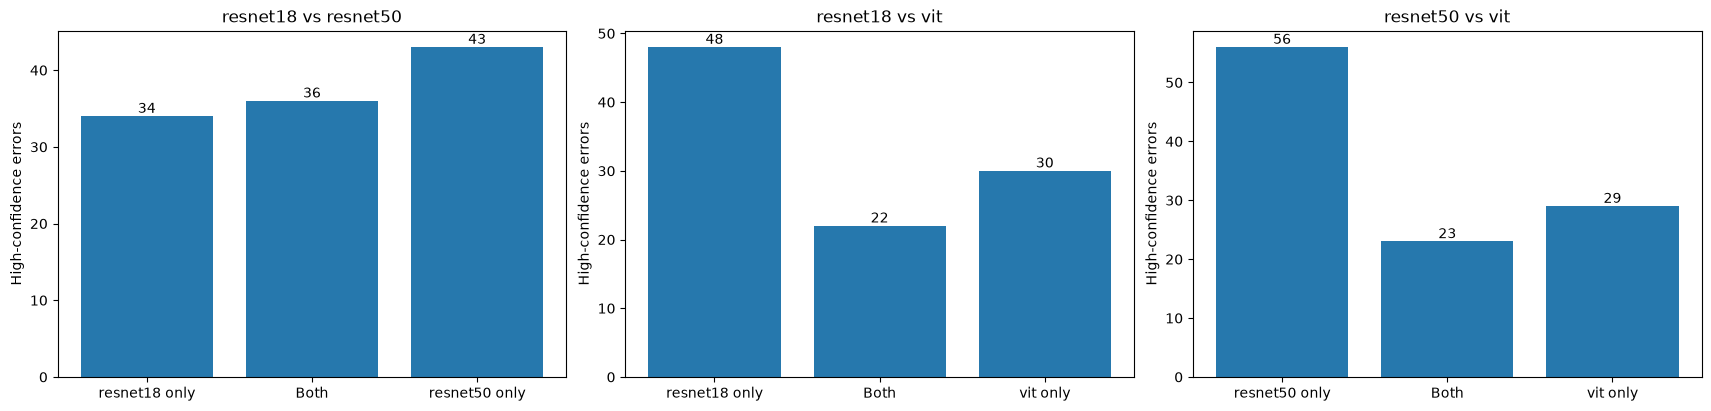

In [2]:
error_ids = [high_confidence_wrong[name] for name in model_names]
shared, union = error_ids[0].copy(), error_ids[0].copy()
for ids in error_ids[1:]:
    shared, union = np.intersect1d(shared, ids), np.union1d(union, ids)
print('Errors shared by all three:', len(shared), 'test IDs:', shared.tolist())
pair_overlap = np.zeros((len(model_names), len(model_names)), dtype=int)
pair_jaccard = np.full_like(pair_overlap, np.nan, dtype=float)
fig, axes = plt.subplots(1, len(pairs), figsize=(17, 4), layout='constrained')
for ax, (i, j) in zip(axes, pairs):
    common, combined = np.intersect1d(error_ids[i], error_ids[j]), np.union1d(error_ids[i], error_ids[j])
    pair_overlap[i, j] = pair_overlap[j, i] = len(common)
    pair_jaccard[i, j] = pair_jaccard[j, i] = len(common) / len(combined) if len(combined) else np.nan
    fractions = [len(common) / len(error_ids[m]) if len(error_ids[m]) else np.nan for m in (i, j)]
    print(f'{model_names[i]} / {model_names[j]}: shared {len(common)}, fractions {fractions[0]:.1%} / {fractions[1]:.1%}, Jaccard {pair_jaccard[i, j]:.1%}')
    if len(common):
        print(f'Same wrong class among shared errors: {(predicted[i, common] == predicted[j, common]).mean():.1%}')
    counts = [len(error_ids[i]) - len(common), len(common), len(error_ids[j]) - len(common)]
    ax.bar([f'{model_names[i]} only', 'Both', f'{model_names[j]} only'], counts)
    ax.bar_label(ax.containers[0])
    ax.set(ylabel='High-confidence errors', title=f'{model_names[i]} vs {model_names[j]}')
for m, ids in enumerate(error_ids):
    pair_overlap[m, m], pair_jaccard[m, m] = len(ids), 1 if len(ids) else np.nan
plt.show()


Compare pairwise high-confidence-error counts together with Jaccard overlap, which accounts for different cohort sizes. ResNet18 and ResNet50 share 36 errors with 31.9% Jaccard overlap, versus 22 and 23 errors and about 21–22% overlap for the CNN–ViT pairs. The CNNs share more of their confident failures, but their non-shared errors also show that the checkpoints are not interchangeable.

## A · Shared and exclusive errors — all 39 shared errors; mark cases with ≥90% confidence in every model; class IDs listed below

Shared errors: 39 with ≥90% confidence in all models: 18
Classes: {0: 'basophil', 1: 'eosinophil', 2: 'erythroblast', 3: 'immature granulocytes', 4: 'lymphocyte', 5: 'monocyte', 6: 'neutrophil', 7: 'platelet'}


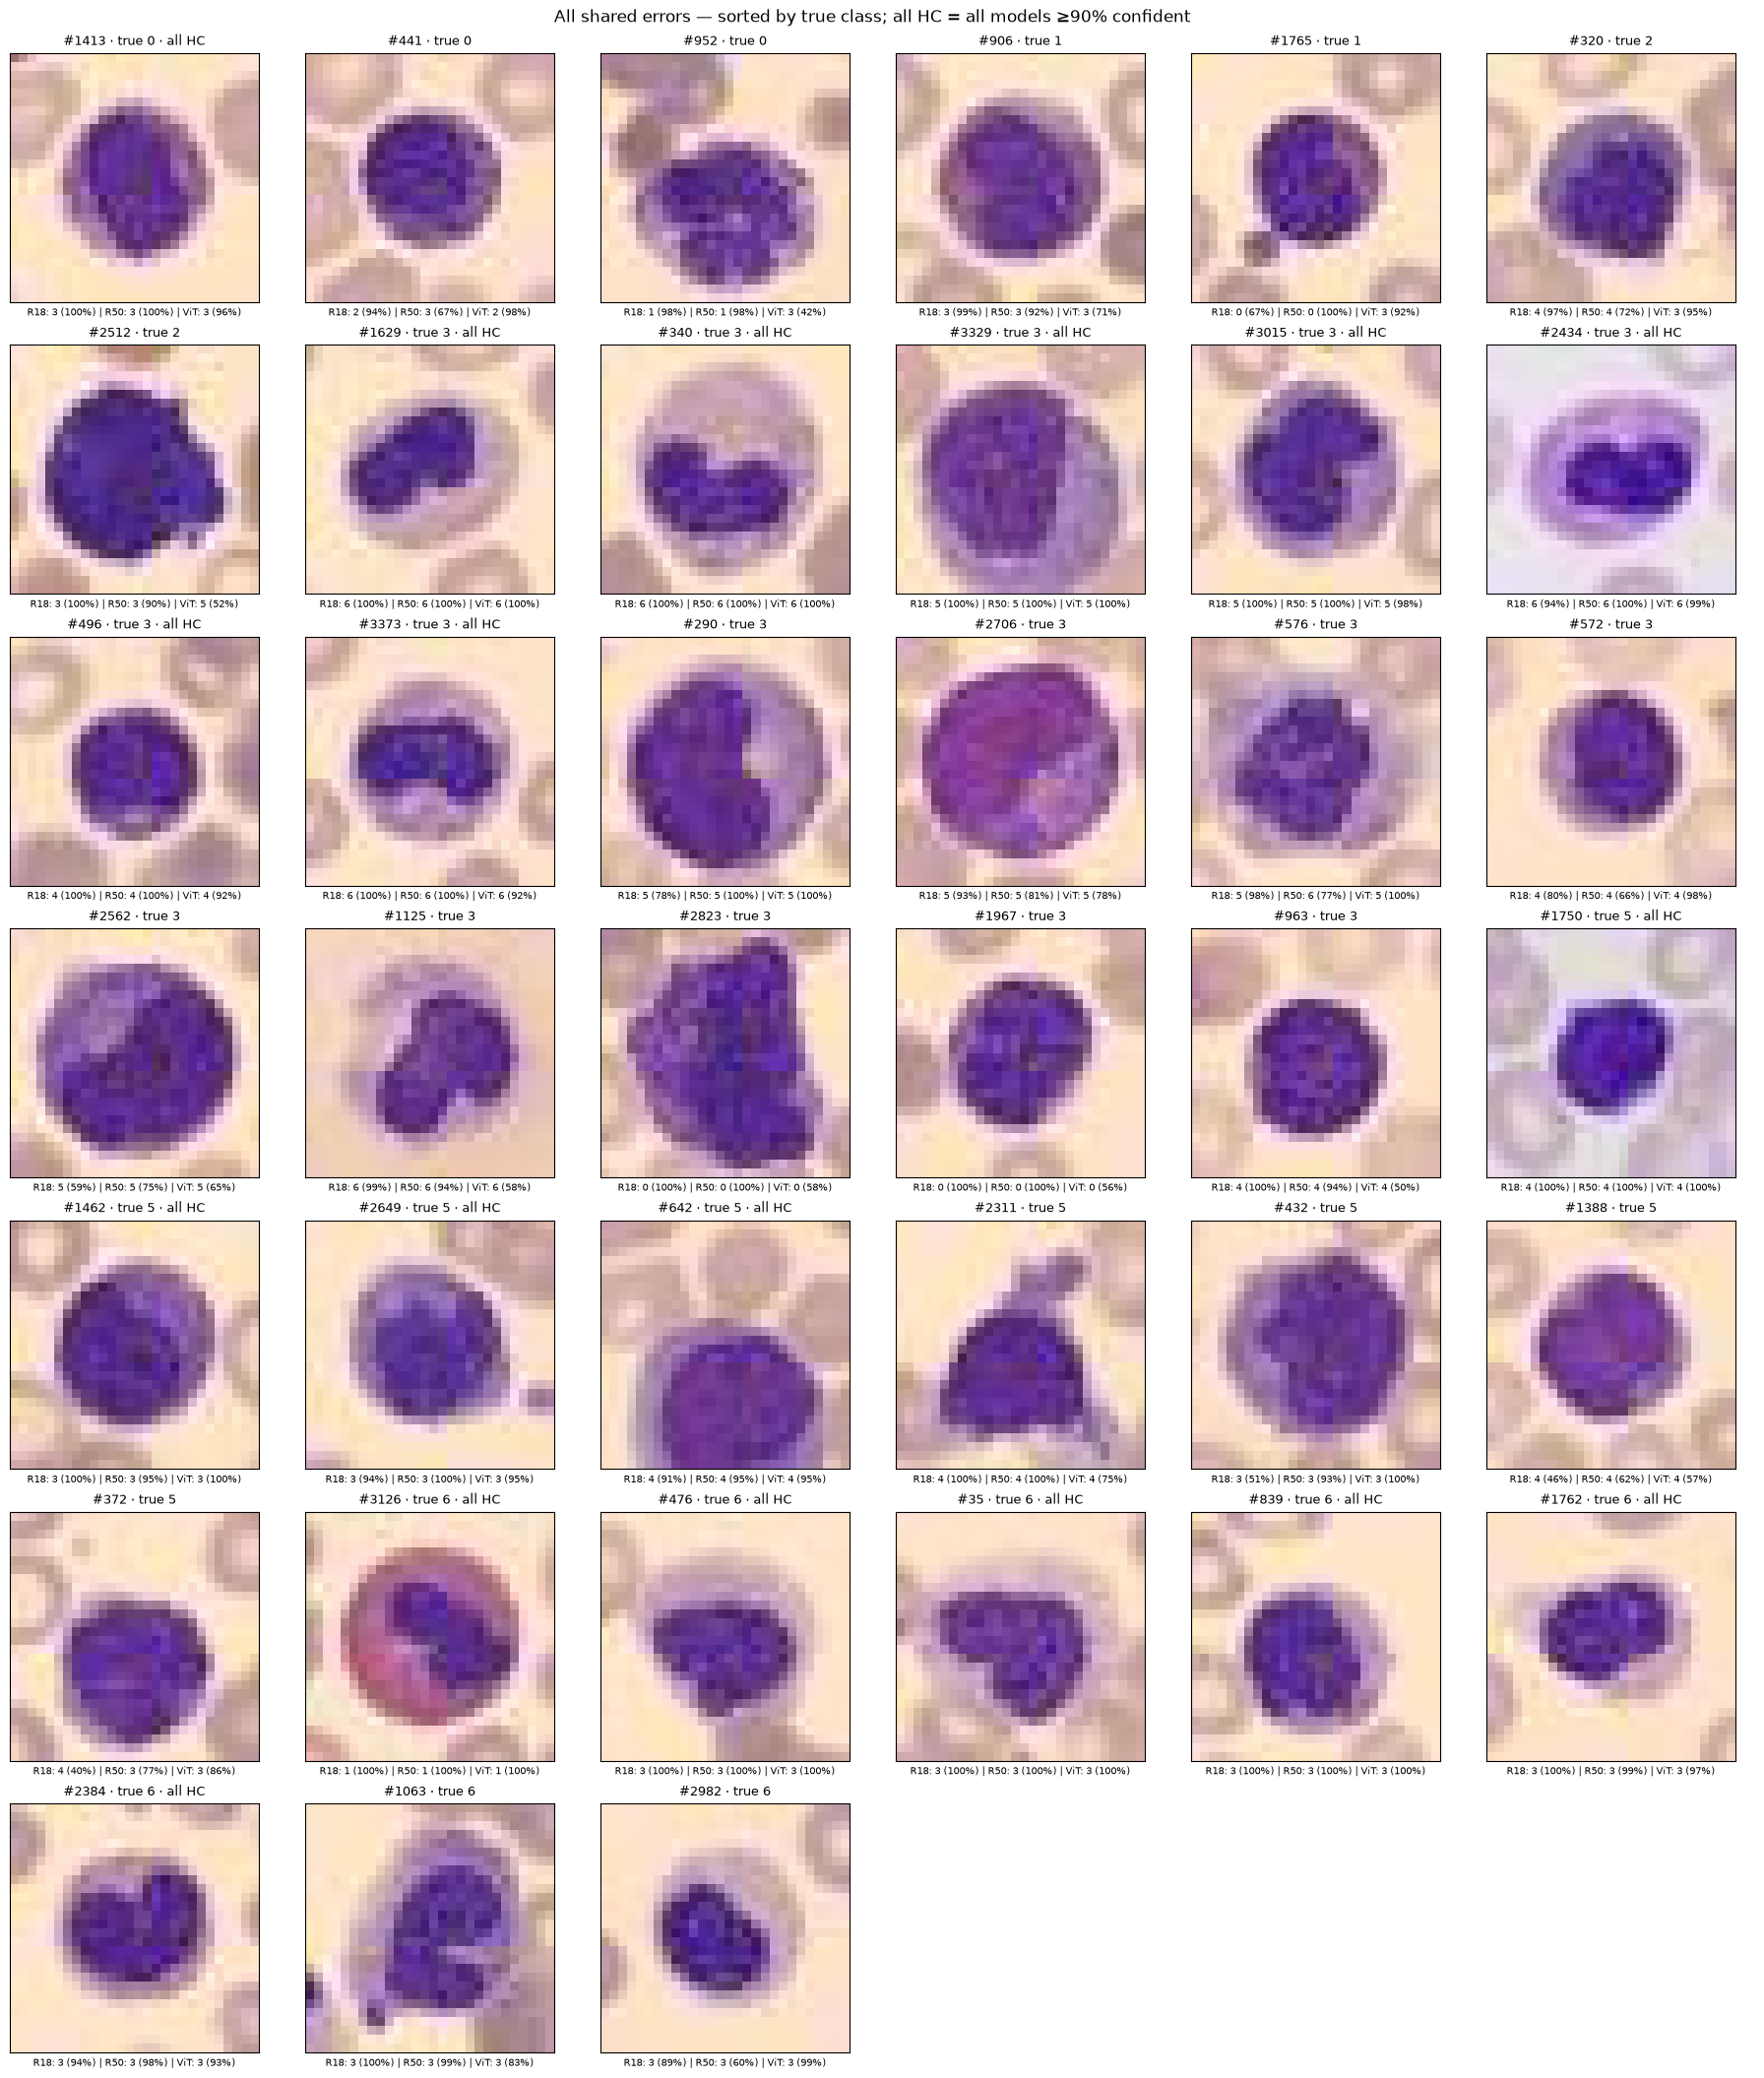

In [3]:
wrong = ~correct
high_wrong = wrong & (confidence >= threshold)
common_wrong = np.flatnonzero(wrong.all(0))
common_hc = np.flatnonzero(high_wrong.all(0))
exclusive_hc = [np.flatnonzero(high_wrong[m] & (wrong.sum(0) == 1)) for m in range(len(model_names))]
print('Shared errors:', len(common_wrong), 'with ≥90% confidence in all models:', len(common_hc))
print('Classes:', dict(enumerate(class_names)))

def gallery(ids, title, columns=6):
    rows = max(1, int(np.ceil(len(ids) / columns)))
    fig, axes = plt.subplots(rows, columns, figsize=(18, 3 * rows), squeeze=False, layout='constrained')
    for ax in axes.flat:
        ax.axis('off')
    for ax, i in zip(axes.flat, ids):
        ax.axis('on')
        ax.imshow(images[i])
        ax.set_title(f'#{i} · true {labels[i]}' + (' · all HC' if high_wrong[:, i].all() else ''), fontsize=9)
        ax.set_xlabel(' | '.join(f'{name}: {predicted[m, i]} ({confidence[m, i]:.0%})'
                                for m, name in enumerate(['R18', 'R50', 'ViT'])), fontsize=7, wrap=True)
        ax.set_xticks([])
        ax.set_yticks([])
    fig.suptitle(title)
    plt.show()

order = np.lexsort((-confidence[:, common_wrong].min(0), labels[common_wrong]))
gallery(common_wrong[order], 'All shared errors — sorted by true class; all HC = all models ≥90% confident')

Look for repeated wrong labels in the shared-error gallery, especially the images marked as highly confident in all models. All models misclassify 39 images, and the 18 shared HC errors receive the same wrong class from all three models, with nine substitutions between immature granulocytes and neutrophils. Agreement therefore leaves recurring class-specific blind spots rather than independently confirming the recorded label.

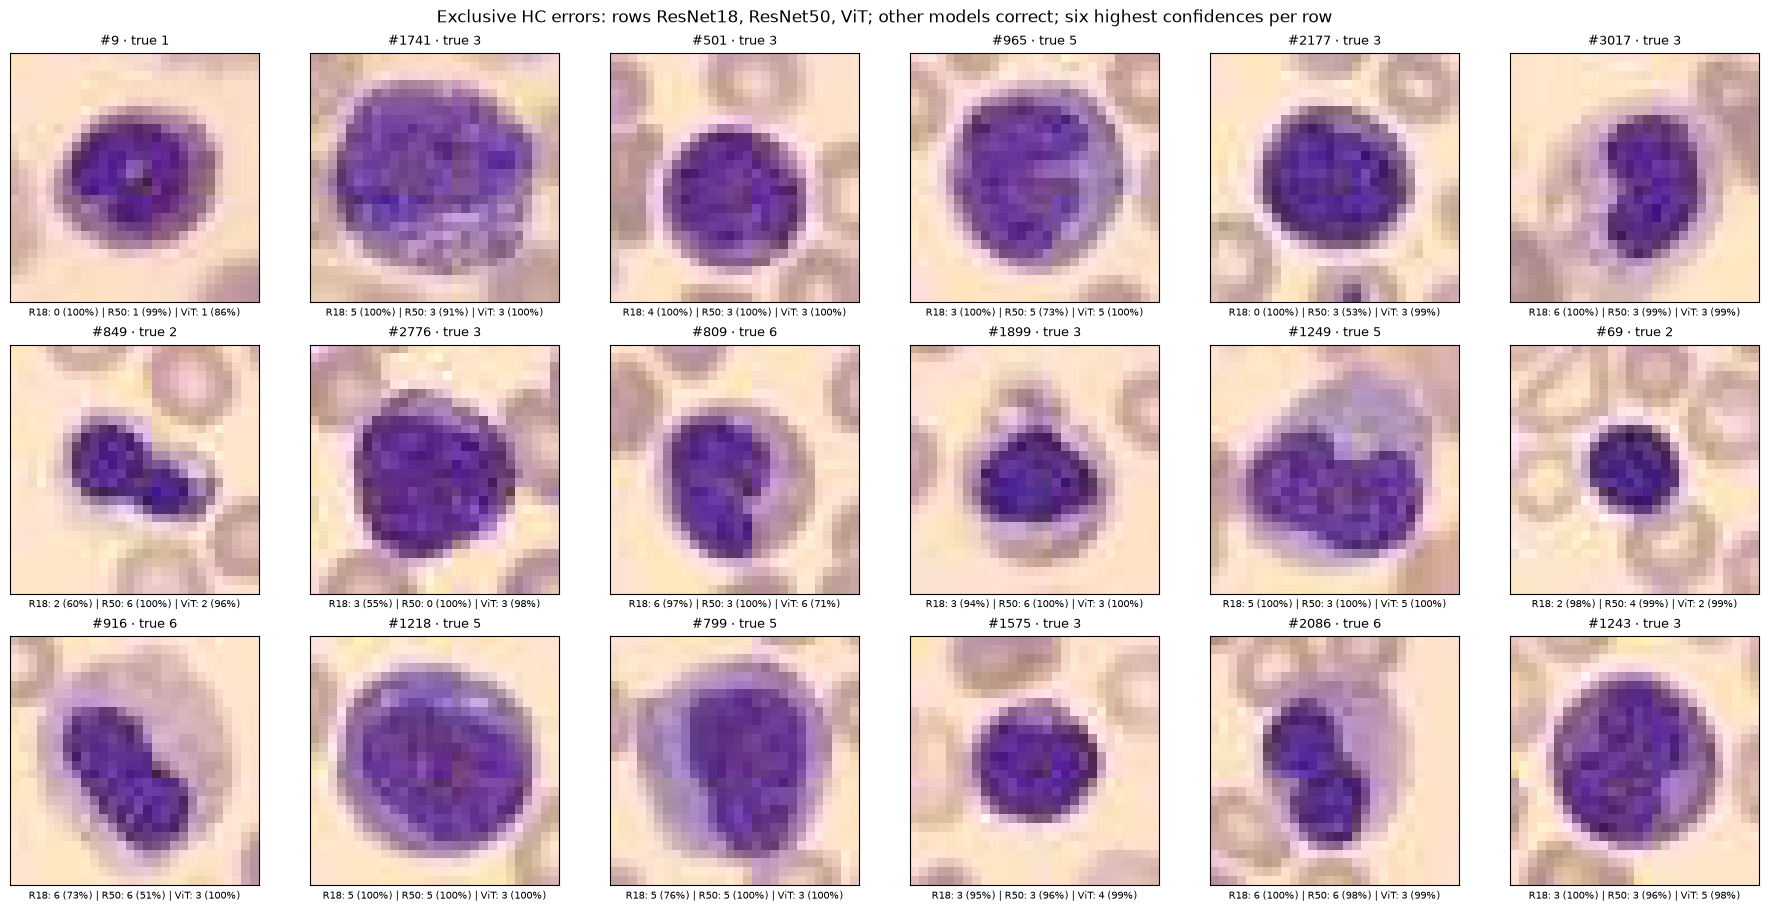

In [4]:
exclusive_examples = np.concatenate([ids[np.argsort(-confidence[m, ids], kind='stable')[:6]]
                                     for m, ids in enumerate(exclusive_hc)])
gallery(exclusive_examples, 'Exclusive HC errors: rows ResNet18, ResNet50, ViT; other models correct; six highest confidences per row')

Compare each row’s selected model with the other two models on the same images. The displayed high-confidence examples are wrong only for ResNet18, only for ResNet50 or only for ViT, while the other models classify them correctly. These exclusive failures show complementary behavior, but confidence-selected examples cannot establish that voting would resolve the shared errors.

## Per-class high-confidence-error rates — class frequency is included in the denominator

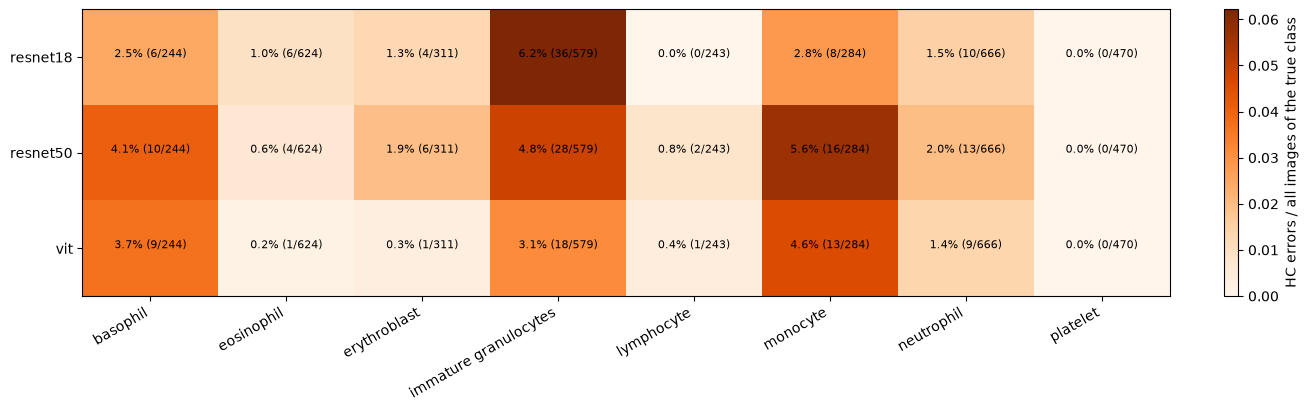

In [5]:
class_sizes = np.bincount(labels, minlength=8)
class_hc_counts = np.stack([np.bincount(labels[ids], minlength=8) for ids in error_ids])
class_hc_rates = class_hc_counts / class_sizes
fig, ax = plt.subplots(figsize=(13, 4), layout='constrained')
im = ax.imshow(class_hc_rates, cmap='Oranges', vmin=0, aspect='auto')
ax.set(xticks=range(8), xticklabels=class_names, yticks=range(3), yticklabels=model_names)
plt.setp(ax.get_xticklabels(), rotation=30, ha='right')
for m in range(3):
    for c in range(8):
        ax.text(c, m, f'{class_hc_rates[m,c]:.1%} ({class_hc_counts[m,c]}/{class_sizes[c]})', ha='center', fontsize=8)
fig.colorbar(im, ax=ax, label='HC errors / all images of the true class')
plt.show()

Compare HC-error rates within each true class rather than raw error counts. ResNet18 reaches 6.22% for immature granulocytes versus 2.05% overall, while monocytes have the highest rates for ResNet50 and ViT at 5.63% and 4.58%. Class frequency alone therefore does not explain the error concentration, and the differing rankings indicate checkpoint-specific weaknesses.

## True class → wrong predicted class — counts and percentages within each model's high-confidence errors, not class-specific error rates

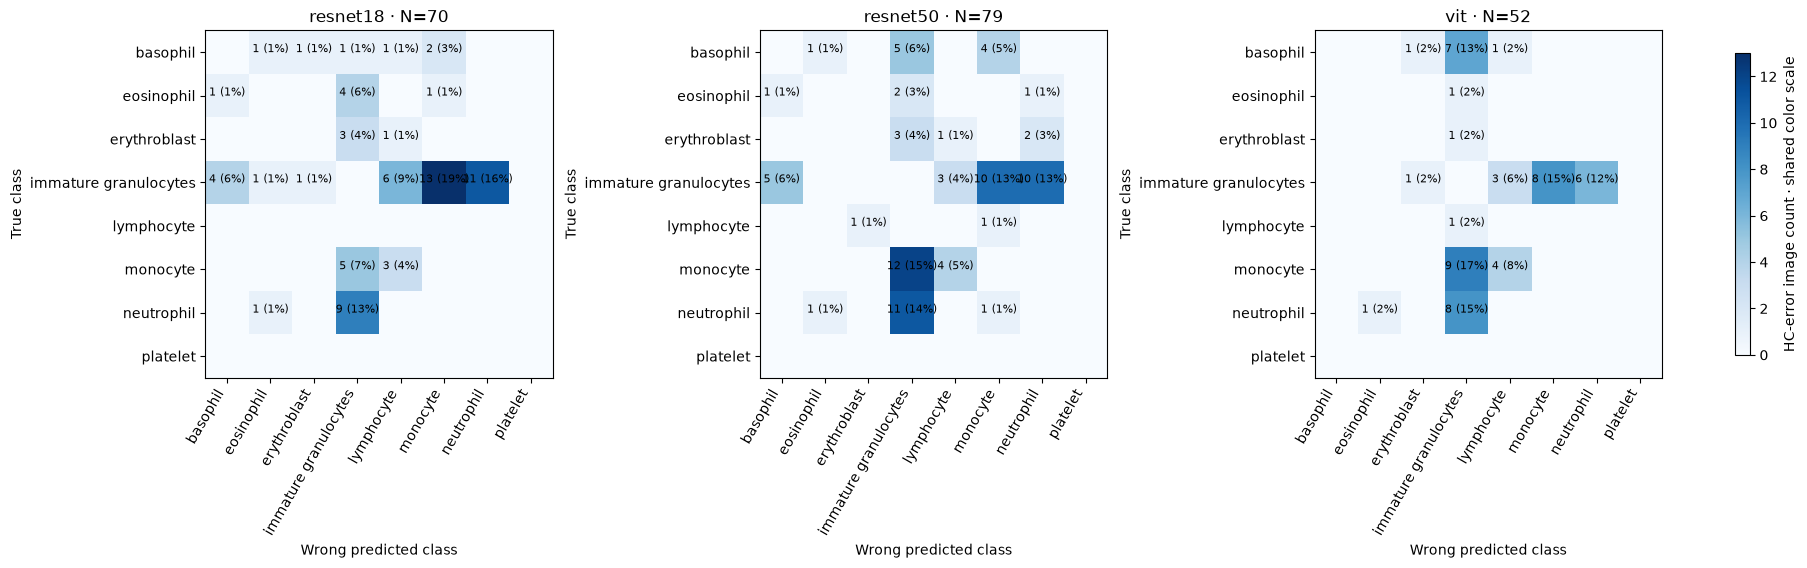

In [6]:
confusions = np.zeros((3, 8, 8), dtype=int)
for m, ids in enumerate(error_ids):
    np.add.at(confusions[m], (labels[ids], predicted[m, ids]), 1)
fig, axes = plt.subplots(1, 3, figsize=(18, 6), layout='constrained')
for m, ax in enumerate(axes):
    im = ax.imshow(confusions[m], cmap='Blues', vmin=0, vmax=confusions.max())
    ax.set(title=f'{model_names[m]} · N={len(error_ids[m])}', xlabel='Wrong predicted class', ylabel='True class',
           xticks=range(8), xticklabels=class_names, yticks=range(8), yticklabels=class_names)
    plt.setp(ax.get_xticklabels(), rotation=60, ha='right')
    for c,d in zip(*np.nonzero(confusions[m])):
        ax.text(d,c,f'{confusions[m,c,d]} ({confusions[m,c,d]/len(error_ids[m]):.0%})',ha='center',fontsize=8)
fig.colorbar(im, ax=axes, shrink=.65, label='HC-error image count · shared color scale')
plt.show()

Read the true-to-predicted class counts to identify recurring substitutions, without treating them as per-class error rates. Immature granulocytes occur on either side of 58/70 ResNet18 error pairs, 61/79 ResNet50 pairs and 45/52 ViT pairs. These failures concentrate around particular class competitions, while the later class-rate view is needed to separate that concentration from class frequency.

### Focus: immature granulocytes ↔ neutrophils

In [7]:
rows=['| Model | True → predicted | All errors / true class | HC errors / true class |','|---|---|---:|---:|']
for m,name in enumerate(model_names):
    for source,destination in [(3,6),(6,3)]:
        selected=(labels==source)&(predicted[m]==destination)
        n=int((labels==source).sum());hc=int((selected&(confidence[m]>=threshold)).sum())
        rows.append(f'| {name} | {class_names[source]} → {class_names[destination]} | {selected.sum()}/{n} ({selected.sum()/n:.1%}) | {hc}/{n} ({hc/n:.1%}) |')
display(Markdown('\n'.join(rows)))

| Model | True → predicted | All errors / true class | HC errors / true class |
|---|---|---:|---:|
| resnet18 | immature granulocytes → neutrophil | 16/579 (2.8%) | 11/579 (1.9%) |
| resnet18 | neutrophil → immature granulocytes | 10/666 (1.5%) | 9/666 (1.4%) |
| resnet50 | immature granulocytes → neutrophil | 17/579 (2.9%) | 10/579 (1.7%) |
| resnet50 | neutrophil → immature granulocytes | 16/666 (2.4%) | 11/666 (1.7%) |
| vit | immature granulocytes → neutrophil | 7/579 (1.2%) | 6/579 (1.0%) |
| vit | neutrophil → immature granulocytes | 16/666 (2.4%) | 8/666 (1.2%) |

**Interpretation:** Compare the two directions using the true-class denominators, distinguishing all errors from the ≥90%-confidence subset. IG→neutrophil errors number 16/17/7 and the reverse direction 10/16/16 for ResNet18/ResNet50/ViT, with many confidently wrong in both directions. This localizes an informative class competition but neither verifies the dataset labels nor establishes which cell morphology caused it.

<a id="story-2"></a>
## 2 · Can we trust confidence?

**Question:** Does a high reported probability imply correctness, and how do wrong images compare with correct images at nearly the same confidence?

**Evidence:** Reliability uses the whole TEST set; the gallery uses one-to-one within-model, same-true-class matching with confidence gap ≤1 percentage point, prioritizing smaller gaps and using RGB distance only as a tiny tie-break.

## Reliability diagram — equal-width confidence bins; ECE weighted by bin counts; empty bins omitted

resnet18: accuracy=96.61%, mean confidence=98.73%, ECE=0.0219
resnet50: accuracy=95.73%, mean confidence=98.66%, ECE=0.0298
vit: accuracy=96.99%, mean confidence=98.62%, ECE=0.0167


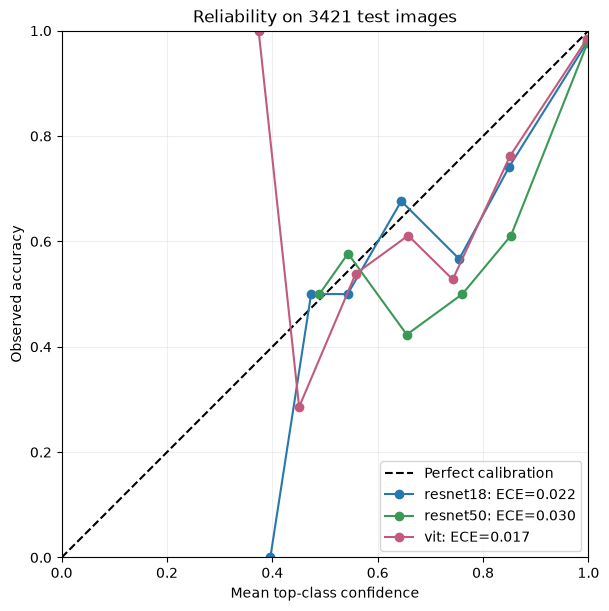

In [8]:
fig, ax = plt.subplots(figsize=(7, 6), layout='constrained')
ax.plot([0, 1], [0, 1], 'k--', label='Perfect calibration')
for m, name in enumerate(model_names):
    groups = bin_ids(confidence[m])
    occupied = [groups == b for b in range(n_bins) if (groups == b).any()]
    x = np.array([confidence[m, mask].mean() for mask in occupied])
    y = np.array([correct[m, mask].mean() for mask in occupied])
    counts = np.array([mask.sum() for mask in occupied])
    ece = np.sum(counts * np.abs(y - x)) / len(labels)
    ax.plot(x, y, 'o-', label=f'{name}: ECE={ece:.3f}')
    print(f'{name}: accuracy={correct[m].mean():.2%}, mean confidence={confidence[m].mean():.2%}, ECE={ece:.4f}')
ax.set(xlabel='Mean top-class confidence', ylabel='Observed accuracy',
       title=f'Reliability on {len(labels)} test images', xlim=(0, 1), ylim=(0, 1))
ax.set_aspect('equal')
ax.grid(alpha=0.2)
ax.legend()
plt.show()

Compare each reliability curve with the diagonal, where confidence equals observed accuracy. Mean confidence exceeds accuracy by about 2.1 percentage points for ResNet18, 2.9 for ResNet50 and 1.6 for ViT. These test results indicate overconfidence, without establishing its training-time cause, and motivate checking calibration on separate data.

### Confidently wrong beside tightly matched correct images

resnet18: 65/70 errors matched; mean confidence gap 0.106 pp; unmatched 5
resnet50: 78/79 errors matched; mean confidence gap 0.111 pp; unmatched 1
vit: 49/52 errors matched; mean confidence gap 0.139 pp; unmatched 3


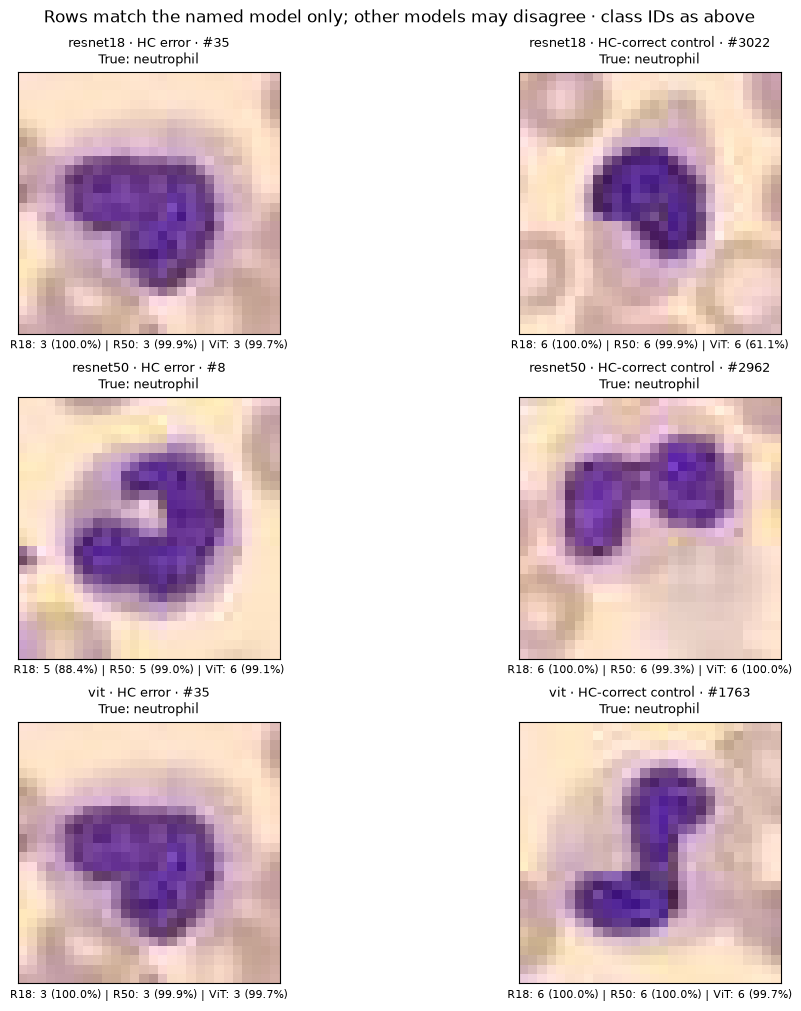

In [9]:
fig,axes=plt.subplots(3,2,figsize=(10,10),layout='constrained')
for m,(name,pairs_m) in enumerate(zip(model_names,matched_pairs)):
    preferred=pairs_m[np.isin(labels[pairs_m[:,0]],[3,6])]
    pair=(preferred if len(preferred) else pairs_m)[0]
    for role,(ax,i) in enumerate(zip(axes[m],pair)):
        ax.imshow(images[i]);ax.set(xticks=[],yticks=[])
        ax.set_title(f'{name} · '+('HC error' if role==0 else 'HC-correct control')+f' · #{i}\nTrue: {class_names[labels[i]]}',fontsize=9)
        ax.set_xlabel(' | '.join(f'{n}: {predicted[k,i]} ({confidence[k,i]:.1%})' for k,n in enumerate(['R18','R50','ViT'])),fontsize=8)
    gaps=targeted[f'matching_{name}_confidence_gaps']
    print(f'{name}: {len(pairs_m)}/{len(error_ids[m])} errors matched; mean confidence gap {100*gaps.mean():.3f} pp; unmatched {len(error_ids[m])-len(pairs_m)}')
fig.suptitle('Rows match the named model only; other models may disagree · class IDs as above')
plt.show()

**Interpretation:** Compare each error/control pair within its named model, then inspect how the other two models respond to those same images. The tighter one-to-one match retains 65/70, 78/79 and 49/52 HC errors with mean confidence gaps of approximately 0.11, 0.11 and 0.14 percentage points. Visually plausible, similarly confident correct controls show why confidence alone cannot identify these mistakes, while unmatched errors limit generalization of the paired analyses.

<a id="story-3"></a>
## 3 · Which visual changes destabilize predictions?

**Question:** Which changes alter decisions or correctness, and is the apparent noise advantage separable from resizing?

**Evidence:** Start with the two common-scale grids in [stability_analysis.ipynb](stability_analysis.ipynb): label-change rate and accuracy across all 3,421 images and all ten severity levels. The selected examples below show all eight probabilities; the balanced 96-image interpolation probe is a targeted control, not a replacement population estimate.

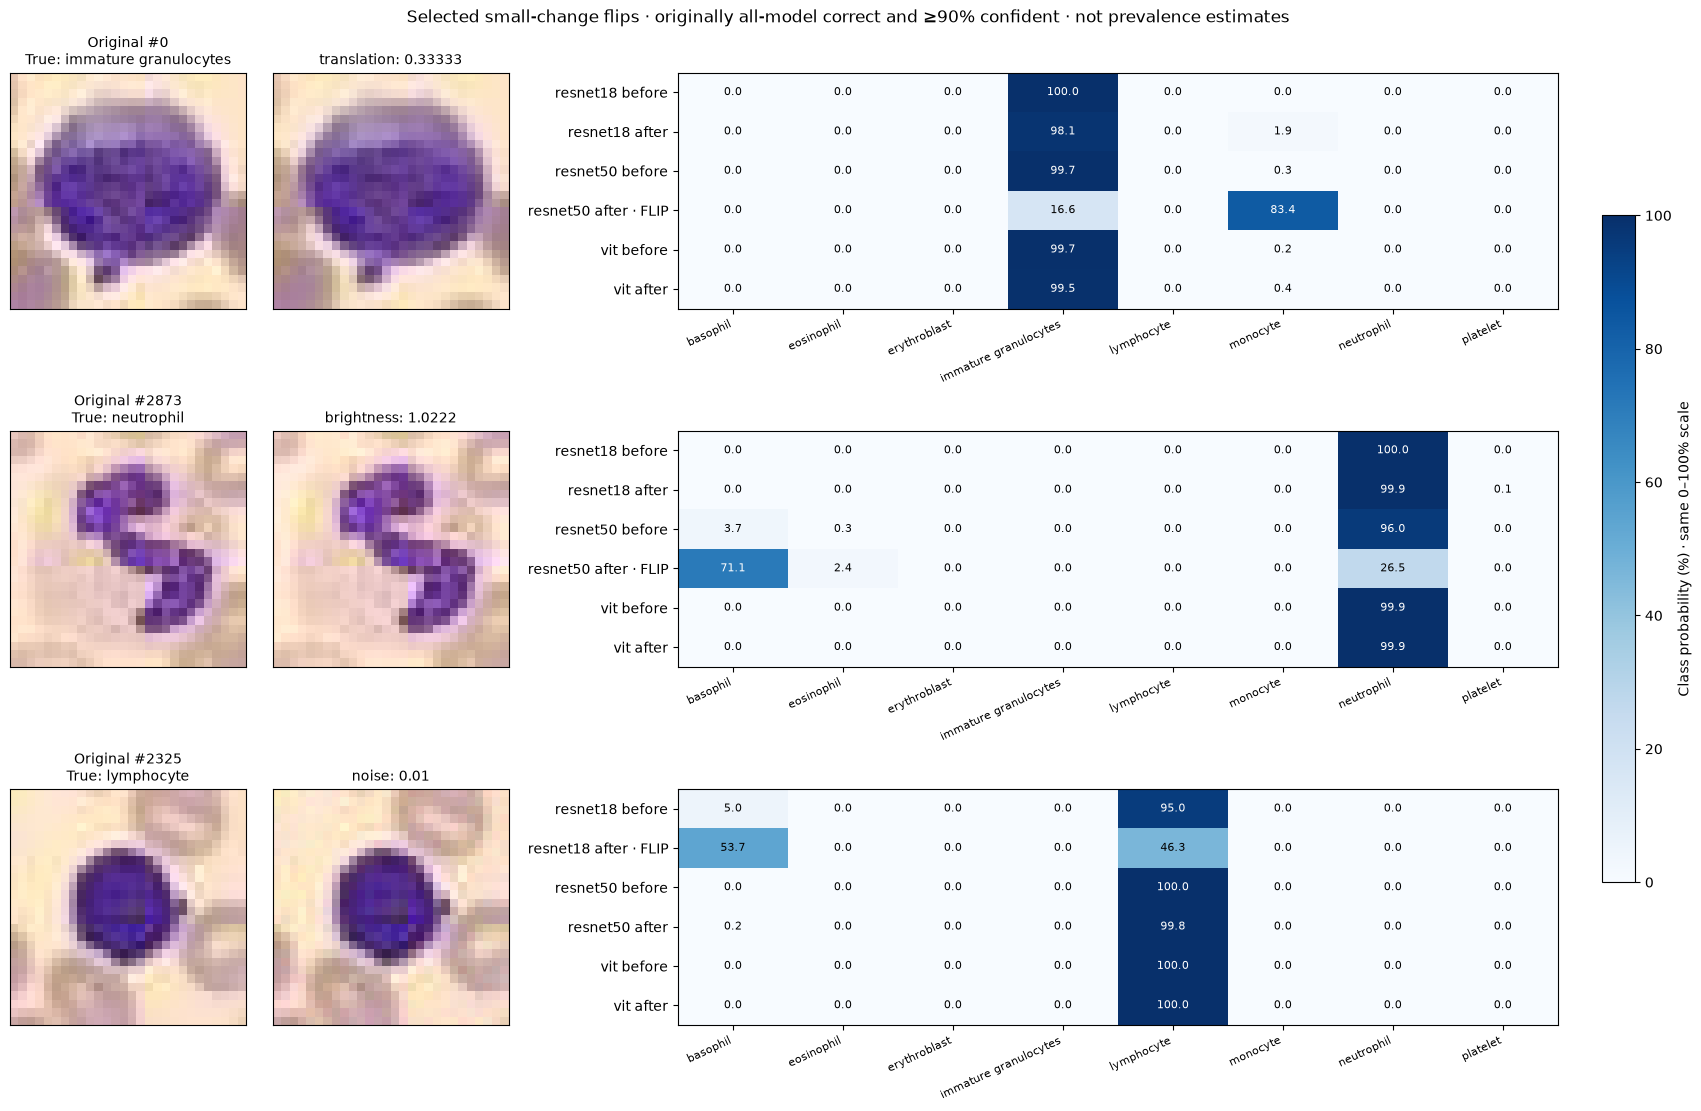

In [10]:
ids=targeted['examples_ids'];before=targeted['examples_baseline'];after=targeted['examples_probabilities']
fig,axes=plt.subplots(3,3,figsize=(17,11),gridspec_kw={'width_ratios':[1,1,3.5]},layout='constrained')
for j,i in enumerate(ids):
    kind,level=str(targeted['examples_kinds'][j]),targeted['examples_levels'][j]
    for ax,im,title in [(axes[j,0],images[i],f'Original #{i}\nTrue: {class_names[labels[i]]}'),(axes[j,1],targeted['examples_images'][j],f'{kind}: {level:.5g}')]:
        ax.imshow(im);ax.set_title(title,fontsize=10);ax.set(xticks=[],yticks=[])
    matrix=np.stack([before[:,j],after[:,j]],axis=1).reshape(6,8)*100
    ax=axes[j,2];im=ax.imshow(matrix,vmin=0,vmax=100,cmap='Blues',aspect='auto')
    row_labels=[f'{name} {role}'+(' · FLIP' if role=='after' and before[m,j].argmax()!=after[m,j].argmax() else '') for m,name in enumerate(model_names) for role in ['before','after']]
    ax.set(yticks=range(6),yticklabels=row_labels,xticks=range(8),xticklabels=class_names)
    plt.setp(ax.get_xticklabels(),rotation=25,ha='right',fontsize=8)
    for r in range(6):
        for c in range(8):ax.text(c,r,f'{matrix[r,c]:.1f}',ha='center',va='center',fontsize=8,color='white' if matrix[r,c]>60 else 'black')
fig.colorbar(im,ax=axes[:,2],shrink=.7,label='Class probability (%) · same 0–100% scale')
fig.suptitle('Selected small-change flips · originally all-model correct and ≥90% confident · not prevalence estimates')
plt.show()

Compare each original/transformed image with the before/after rows for all eight class probabilities, noting the explicitly marked label flips. A one-third-pixel translation, brightness factor 1.0222 and noise σ=0.01 each flip at least one previously ≥90%-confident correct prediction. These deterministically selected counterexamples demonstrate local instability, not typical failure rates or preserved clinical validity of every edit.

### Noise control: identical noisy 28×28 images, common interpolation

Balanced 96 TEST images (12/class), three noise repeats per image and severity; ResNet18/ViT use common PIL nearest/bilinear/bicubic resizing to 224, while ResNet50 stays native 28 as a reference. Native cached arms were reused only after numerical/label equivalence checks where an alternative resize implementation was used. Shaded 95% intervals resample **images within true class**, keeping repeats and before/after observations paired.

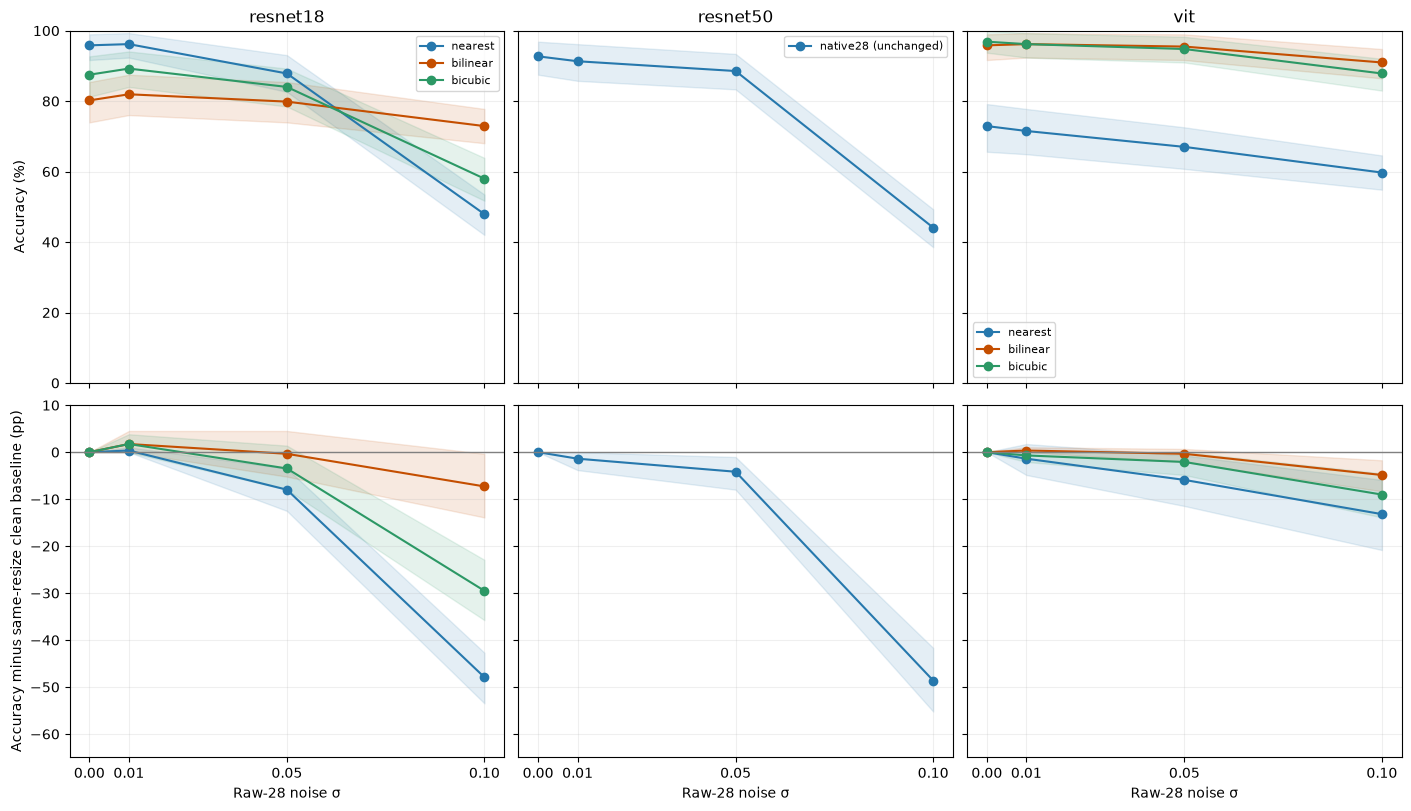

resnet18 nearest: clean 95.8%, σ=.1 47.9%; bilinear: clean 80.2%, σ=.1 72.9%; bicubic: clean 87.5%, σ=.1 58.0%
vit nearest: clean 72.9%, σ=.1 59.7%; bilinear: clean 95.8%, σ=.1 91.0%; bicubic: clean 96.9%, σ=.1 87.8%


In [11]:
q=targeted['interpolation_probabilities'];ids=targeted['interpolation_ids'];noise_levels=targeted['interpolation_noise_levels']
noise_x=np.r_[0,noise_levels]
# One observation per image: average the three repeats before uncertainty estimation.
acc=np.concatenate([(q[:,:,0].argmax(-1)==labels[ids])[:,:,None,:],(q[:,:,1:].reshape(3,3,3,3,len(ids),8).argmax(-1)==labels[ids]).mean(3)],axis=2)
rng=np.random.default_rng(42)
draws=np.column_stack([rng.choice(np.flatnonzero(labels[ids]==c),size=(2000,12)) for c in range(8)])
fig,axes=plt.subplots(2,3,figsize=(14,8),sharex=True,sharey='row',layout='constrained')
resize_colors=['#2678ad','#c44e00','#2c9865']
for m in range(3):
    modes=range(3) if m!=1 else [0]
    for j in modes:
        values=100*acc[m,j];change=values-values[0]
        title=str(targeted['interpolation_modes'][j]) if m!=1 else 'native28 (unchanged)'
        for row,data in enumerate([values,change]):
            ci=np.quantile(data[:,draws].mean(-1),[.025,.975],axis=1)
            axes[row,m].plot(noise_x,data.mean(-1),'o-',label=title,color=resize_colors[j])
            axes[row,m].fill_between(noise_x,ci[0],ci[1],alpha=.12,color=resize_colors[j])
    axes[0,m].set(title=model_names[m],ylim=(0,100));axes[0,m].legend(fontsize=8)
    axes[1,m].axhline(0,color='gray',lw=1);axes[1,m].set(xlabel='Raw-28 noise σ',ylim=(-65,10),xticks=noise_x)
    for ax in axes[:,m]:ax.grid(alpha=.2)
axes[0,0].set_ylabel('Accuracy (%)');axes[1,0].set_ylabel('Accuracy minus same-resize clean baseline (pp)')
plt.show()
for m in [0,2]:
    print(model_names[m],'; '.join(f'{mode}: clean {100*acc[m,j,0].mean():.1f}%, σ=.1 {100*acc[m,j,-1].mean():.1f}%' for j,mode in enumerate(targeted['interpolation_modes'])))

**Interpretation:** Compare absolute accuracy in the top row and loss from each interpolation’s own clean baseline below, rather than comparing noise curves alone. At σ=0.1, native ResNet18/ViT lose 47.9/4.9 accuracy points, versus 7.3/4.9 with common bilinear resizing, but ResNet18’s clean accuracy simultaneously falls from 95.8% to 80.2%. Resizing is therefore a substantial confound of the observed noise gap, not proof that interpolation alone explains it or that the architectures are now fairly isolated.

## What drives the accuracy change? — interactive explorer

Compare recovered errors above zero with new errors below zero; dark orange marks new errors at ≥90% confidence. All panels use the same test-image denominator and linked axes, including while zooming. Choose a transformation, then wheel or drag to zoom; use Reset to return to the full range.

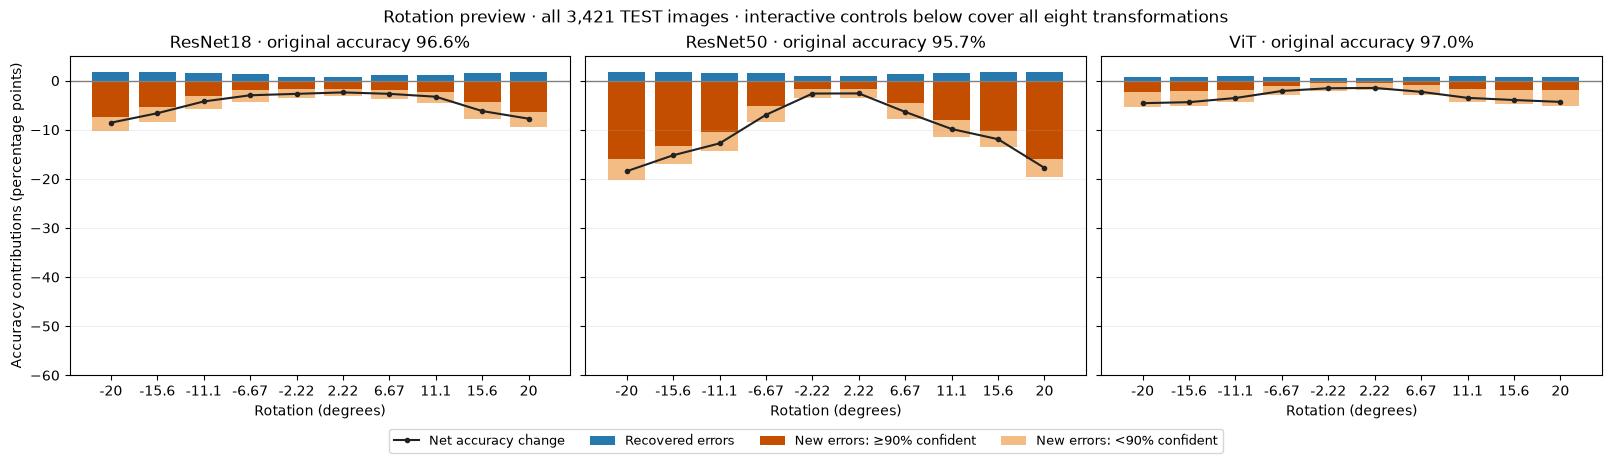

In [12]:
# Correctness changes explain accuracy; a switch between two wrong labels is not a gain or loss.
transition_data = dict(n=len(labels), threshold=threshold, models=['ResNet18', 'ResNet50', 'ViT'], operations={})
operation_names = {'rotation': ('Rotation', 'degrees'), 'translation': ('Translation', 'pixels'),
                   'brightness': ('Brightness', 'factor'), 'blur': ('Blur', 'pixels'),
                   'noise': ('Noise', 'sigma'), 'green_scale': ('Green scaling', 'factor'),
                   'red_scale': ('Red scaling', 'factor'), 'blue_scale': ('Blue scaling', 'factor')}
with np.load('predictions/stability.npz', allow_pickle=False) as saved:
    assert str(saved['split']) == 'test'
    np.testing.assert_array_equal(saved['indices'], np.arange(len(labels)))
    np.testing.assert_array_equal(saved['labels'], labels)
    np.testing.assert_array_equal(saved['baseline'], probabilities)
    was_correct = saved['baseline'].argmax(-1) == labels
    baseline_accuracy = 100 * was_correct.mean(-1)
    transition_data.update(baseline_accuracy=baseline_accuracy.tolist(),
                           baseline_errors=(~was_correct).sum(-1).tolist())
    for kind, (name, unit) in operation_names.items():
        p = saved[kind]
        now_correct = p.argmax(-1) == labels
        new_error = was_correct[:, None, None, :] & ~now_correct
        recovered = ~was_correct[:, None, None, :] & now_correct
        # Each original image has equal weight, including when noise has three repeats.
        counts = lambda mask: mask.mean(2).sum(-1)
        lost, gained = counts(new_error), counts(recovered)
        confident_lost = counts(new_error & (p.max(-1) >= threshold))
        np.testing.assert_allclose(baseline_accuracy[:, None] + 100 * (gained - lost) / len(labels),
                                   100 * now_correct.mean((2, 3)), atol=1e-10)
        assert (confident_lost <= lost).all()
        transition_data['operations'][kind] = dict(name=name, unit=unit, levels=saved[f'levels_{kind}'].tolist(),
            repeats=p.shape[2], lost=lost.tolist(), recovered=gained.tolist(), hc_lost=confident_lost.tolist())
max_loss = max(np.max(op['lost']) for op in transition_data['operations'].values())
max_gain = max(np.max(op['recovered']) for op in transition_data['operations'].values())
transition_data.update(ymin=float(-10 * np.ceil(100 * max_loss / len(labels) / 10)),
                       ymax=float(max(5, 5 * np.ceil(100 * max_gain / len(labels) / 5))))

# A static rotation preview remains readable on GitHub; the explorer below includes all operations.
preview = transition_data['operations']['rotation']
x = np.arange(len(preview['levels']))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True, layout='constrained')
for m, ax in enumerate(axes):
    gained, lost, hc = [100 * np.asarray(preview[key])[m] / len(labels) for key in ['recovered', 'lost', 'hc_lost']]
    ax.bar(x, gained, color='#2678ad', label='Recovered errors')
    ax.bar(x, -hc, color='#c44e00', label=f'New errors: ≥{threshold:.0%} confident')
    ax.bar(x, -(lost - hc), bottom=-hc, color='#f3bc85', label=f'New errors: <{threshold:.0%} confident')
    ax.plot(x, gained - lost, 'o-', color='#222', ms=3, label='Net accuracy change')
    ax.axhline(0, color='gray', lw=1)
    ax.set(title=f'{transition_data["models"][m]} · original accuracy {baseline_accuracy[m]:.1f}%',
           xticks=x, xticklabels=[f'{v:.3g}' for v in preview['levels']], xlabel='Rotation (degrees)',
           ylim=(transition_data['ymin'], transition_data['ymax']))
    ax.grid(axis='y', alpha=0.2)
axes[0].set_ylabel('Accuracy contributions (percentage points)')
fig.legend(*axes[0].get_legend_handles_labels(), loc='outside lower center', ncol=4, fontsize=9)
fig.suptitle(f'Rotation preview · all {len(labels):,} TEST images · interactive controls below cover all eight transformations')
plt.show()


Compare bars above and below zero at the same level, then follow the black line to see which side dominates. At +20° rotation, ResNet50 recovers 60 errors but introduces 668 new ones, 547 of which are ≥90% confident, for a net accuracy loss of 17.8 percentage points. Helpful wrong-to-correct reversals are therefore overwhelmed by new, often confident errors, explaining why the overall accuracy falls despite some original mistakes becoming correct.

In [13]:
import html
from IPython.display import HTML, FileLink, display

# Self-contained HTML/SVG/JavaScript: no CDN, web service, widget backend or extra dependency.
transition_template = r'''<!doctype html>
<html lang="en"><meta charset="utf-8"><meta name="viewport" content="width=device-width, initial-scale=1">
<title>Transformation explorer</title>
<style>
*{box-sizing:border-box}body{font:14px system-ui,sans-serif;color:#252b32;max-width:1500px;margin:16px auto;padding:0 16px}h1{font-size:21px;margin:0}header,.toolbar,.legend{display:flex;align-items:center;flex-wrap:wrap;gap:12px}header{justify-content:space-between;margin-bottom:16px}.toolbar{gap:10px}label{display:flex;align-items:center;gap:8px;color:#58616b}select,button{font:inherit;background:white;border:1px solid #cfd5db;border-radius:5px;padding:5px 9px;color:#252b32}button{cursor:pointer}button:hover{background:#f1f4f7}button:focus-visible,select:focus-visible{outline:2px solid #2678ad}input{width:155px}output{min-width:94px;font-variant-numeric:tabular-nums}.legend{font-size:12px;color:#58616b;margin-bottom:12px;gap:18px}.swatch{display:inline-block;width:12px;height:9px;margin-right:5px}.models{display:grid;grid-template-columns:repeat(3,minmax(250px,1fr));gap:14px}.card{border:1px solid #e1e5e9;border-radius:7px;padding:12px}.model-head{display:flex;align-items:baseline;justify-content:space-between;gap:6px}.model-head h2{font-size:17px;margin:0}.accuracy{font-size:15px;font-weight:600;white-space:nowrap}.delta{font-size:12px;font-weight:400;color:#69737e;margin-left:6px}svg{width:100%;height:auto;touch-action:none;user-select:none;cursor:crosshair}.stats{display:grid;grid-template-columns:repeat(3,1fr);gap:8px;border-top:1px solid #edf0f3;padding-top:8px}.stats span{display:block;color:#69737e;font-size:11px}.stats strong{font-size:17px;font-weight:600;font-variant-numeric:tabular-nums}.footer{display:flex;justify-content:space-between;flex-wrap:wrap;gap:10px;margin-top:12px;color:#69737e;font-size:12px}details{margin-top:14px;color:#58616b;font-size:12px;line-height:1.6}summary{cursor:pointer}details p{max-width:1050px}a{color:#17689c}.selection{fill:#2678ad;fill-opacity:.12;stroke:#2678ad;stroke-dasharray:4 3;pointer-events:none}@media(max-width:850px){.models{grid-template-columns:1fr}header{align-items:flex-start}.toolbar{width:100%}}
</style>
<header><h1>Transformation explorer</h1><div class="toolbar"><select id="transformation" aria-label="Transformation"></select><label>Level <input id="level" aria-label="Transformation level" type="range" min="0" max="9" step="1" value="9"></label><output id="levelLabel" aria-live="polite"></output><button id="zoom-in" aria-label="Zoom in" title="Zoom into the selected level">+</button><button id="zoom-out" aria-label="Zoom out" title="Zoom out">−</button><button id="fit" title="Fit this transformation’s data, using the same axes for all models">Fit</button><button id="reset" title="Restore the shared full range">Reset</button></div></header>
<div class="legend"><span><i class="swatch" style="background:#2678ad"></i>Recovered</span><span><i class="swatch" style="background:#c44e00"></i>New: ≥__THRESHOLD__</span><span><i class="swatch" style="background:#f3bc85"></i>New: &lt;__THRESHOLD__</span><span>━━ Net accuracy change</span></div>
<div id="models" class="models"></div>
<div class="footer"><span id="status"></span><span>Wheel / drag to zoom · double-click to reset</span></div>
<details><summary>How to read · definitions · sources</summary><p>Bars above zero are originally wrong images that become correct; bars below zero are originally correct images that become wrong. Dark orange identifies new errors with confidence ≥__THRESHOLD__. The black line is recovered minus new errors, so it measures the net accuracy change. All contributions use the same full-test denominator, not different correct/wrong group sizes; switches between two wrong labels do not contribute. Header percentages show accuracy at the selected level, with the change from the original prediction beside them; hover for the original accuracy.</p><p>Zoom is linked across all three models. Drag a rectangle or use the wheel to zoom, click a bar or move the slider to inspect a level, use Fit for the current transformation’s range, or Reset / double-click for the full range. Changing transformations resets zoom. Noise counts are means of three realizations, not independent extra images. Transformed inputs may leave the data distribution or change the label: these views describe checkpoint responses, not a correction strategy.</p><p>Design: <a href="https://pmc.ncbi.nlm.nih.gov/articles/PMC7733875/">small multiples</a> · <a href="https://data.europa.eu/apps/data-visualisation-guide/the-information-seeking-mantra">overview, filter, details on demand</a>.</p></details>
<script>
const D=__DATA__;
const select=document.getElementById('transformation'), slider=document.getElementById('level');
for(const [key,p] of Object.entries(D.operations)){const o=document.createElement('option');o.value=key;o.textContent=p.name;select.append(o);}
const G={W:460,H:310,L:42,R:10,T:20,B:38};G.w=G.W-G.L-G.R;G.h=G.H-G.T-G.B;
const full={xmin:-.5,xmax:9.5,ymin:D.ymin,ymax:D.ymax};let view={...full},chosen=9,suppressClickUntil=0;
const fmt=x=>Math.abs(x)<1e-9?'0':Number(x.toPrecision(3)).toString();
const count=x=>Math.abs(x-Math.round(x))<1e-6?Math.round(x).toLocaleString():x.toFixed(1);
const pp=x=>(x>=0?'+':'')+x.toFixed(1)+' pp';
const X=j=>G.L+(j-view.xmin)/(view.xmax-view.xmin)*G.w;
const Y=v=>G.T+(view.ymax-v)/(view.ymax-view.ymin)*G.h;
const invX=x=>view.xmin+(x-G.L)/G.w*(view.xmax-view.xmin);
const invY=y=>view.ymax-(y-G.T)/G.h*(view.ymax-view.ymin);
function bounded(lo,hi,min,max,minSpan){const span=Math.min(max-min,Math.max(minSpan,hi-lo));lo=Math.max(min,Math.min((lo+hi-span)/2,max-span));return[lo,lo+span];}
function setView(xmin,xmax,ymin,ymax){[view.xmin,view.xmax]=bounded(xmin,xmax,full.xmin,full.xmax,1.5);[view.ymin,view.ymax]=bounded(ymin,ymax,full.ymin,full.ymax,.5);if(chosen<view.xmin||chosen>view.xmax){chosen=Math.max(0,Math.min(9,Math.round((view.xmin+view.xmax)/2)));slider.value=chosen;}render();}
function zoom(factor,cx=chosen,cy=0){setView(cx+(view.xmin-cx)*factor,cx+(view.xmax-cx)*factor,cy+(view.ymin-cy)*factor,cy+(view.ymax-cy)*factor);}
function reset(){view={...full};render();}
function ticks(lo,hi){const raw=(hi-lo)/5,power=10**Math.floor(Math.log10(raw)),r=raw/power,step=(r<=1?1:r<=2?2:r<=5?5:10)*power,result=[];for(let v=Math.ceil(lo/step)*step;v<=hi+step*1e-8;v+=step)result.push(v);return result;}
function chart(p,m){
 const dx=G.w/(view.xmax-view.xmin),clip=`clip${m}`;
 let s=`<svg viewBox="0 0 ${G.W} ${G.H}" data-model="${m}" role="img" aria-label="${D.models[m]}: zoomable accuracy contributions"><defs><clipPath id="${clip}"><rect x="${G.L}" y="${G.T}" width="${G.w}" height="${G.h}"/></clipPath></defs>`;
 s+=`<g clip-path="url(#${clip})"><rect x="${X(chosen)-dx/2}" y="${G.T}" width="${dx}" height="${G.h}" fill="#f5f7fa"/></g>`;
 for(const tick of ticks(view.ymin,view.ymax))s+=`<line x1="${G.L}" x2="${G.W-G.R}" y1="${Y(tick)}" y2="${Y(tick)}" stroke="${Math.abs(tick)<1e-8?'#969fa9':'#edf0f3'}"/><text x="${G.L-6}" y="${Y(tick)+4}" text-anchor="end" font-size="11" fill="#69737e">${fmt(tick)}</text>`;
 s+=`<text x="${G.L}" y="12" font-size="10" fill="#69737e">Accuracy contributions (pp)</text><g clip-path="url(#${clip})">`;
 for(let j=0;j<10;j++){
  const gain=100*p.recovered[m][j]/D.n,loss=100*p.lost[m][j]/D.n,hc=100*p.hc_lost[m][j]/D.n,a=X(j)-.33*dx,b=.66*dx;
  s+=`<g data-step="${j}" style="cursor:pointer"><title>${p.name} ${fmt(p.levels[j])} ${p.unit}: ${count(p.lost[m][j])} new (${count(p.hc_lost[m][j])} confident); ${count(p.recovered[m][j])} recovered</title><rect x="${X(j)-dx/2}" y="${G.T}" width="${dx}" height="${G.h}" fill="transparent"/><rect x="${a}" y="${Y(gain)}" width="${b}" height="${Y(0)-Y(gain)}" fill="#2678ad"/><rect x="${a}" y="${Y(0)}" width="${b}" height="${Y(-hc)-Y(0)}" fill="#c44e00"/><rect x="${a}" y="${Y(-hc)}" width="${b}" height="${Y(-loss)-Y(-hc)}" fill="#f3bc85"/></g>`;
 }
 const points=p.levels.map((_,j)=>`${X(j)},${Y(100*(p.recovered[m][j]-p.lost[m][j])/D.n)}`).join(' ');
 s+=`<polyline points="${points}" fill="none" stroke="#222" stroke-width="2" pointer-events="none"/><circle cx="${X(chosen)}" cy="${Y(100*(p.recovered[m][chosen]-p.lost[m][chosen])/D.n)}" r="4" fill="#222" pointer-events="none"/></g>`;
 const first=Math.max(0,Math.ceil(view.xmin)),last=Math.min(9,Math.floor(view.xmax)),stride=Math.max(1,Math.ceil((last-first+1)/6));
 for(let j=first;j<=last;j++)if((j-first)%stride===0||j===last||j===chosen)s+=`<text x="${X(j)}" y="${G.H-20}" text-anchor="middle" font-size="10" fill="#69737e">${fmt(p.levels[j])}</text>`;
 return s+`<text x="${G.L+G.w/2}" y="${G.H-3}" text-anchor="middle" font-size="10" fill="#69737e">${p.unit}</text></svg>`;
}
function localPoint(svg,e){const p=svg.createSVGPoint();p.x=e.clientX;p.y=e.clientY;return p.matrixTransform(svg.getScreenCTM().inverse());}
function inside(p){return p.x>=G.L&&p.x<=G.W-G.R&&p.y>=G.T&&p.y<=G.H-G.B;}
function bindZoom(svg){
 svg.addEventListener('wheel',e=>{const p=localPoint(svg,e);if(!inside(p))return;e.preventDefault();zoom(Math.exp(Math.max(-1,Math.min(1,e.deltaY*.002))),invX(p.x),invY(p.y));},{passive:false});
 svg.ondblclick=e=>{e.preventDefault();reset();};
 svg.onclick=e=>{if(Date.now()<suppressClickUntil)return;const p=localPoint(svg,e);if(inside(p)){chosen=Math.max(0,Math.min(9,Math.round(invX(p.x))));slider.value=chosen;render();}};
 let start=null,box=null;
 svg.onpointerdown=e=>{const p=localPoint(svg,e);if(e.button!==0||!inside(p))return;e.preventDefault();start=p;try{svg.setPointerCapture(e.pointerId);}catch{}box=document.createElementNS('http://www.w3.org/2000/svg','rect');box.setAttribute('class','selection');svg.append(box);};
 svg.onpointermove=e=>{if(!start)return;const p=localPoint(svg,e),x=Math.max(G.L,Math.min(G.W-G.R,p.x)),y=Math.max(G.T,Math.min(G.H-G.B,p.y));for(const[k,v]of Object.entries({x:Math.min(start.x,x),y:Math.min(start.y,y),width:Math.abs(x-start.x),height:Math.abs(y-start.y)}))box.setAttribute(k,v);};
 svg.onpointerup=e=>{if(!start)return;const p=localPoint(svg,e),x=Math.max(G.L,Math.min(G.W-G.R,p.x)),y=Math.max(G.T,Math.min(G.H-G.B,p.y)),a=start;start=null;box.remove();if(Math.abs(x-a.x)>6&&Math.abs(y-a.y)>6){suppressClickUntil=Date.now()+250;setView(invX(Math.min(x,a.x)),invX(Math.max(x,a.x)),invY(Math.max(y,a.y)),invY(Math.min(y,a.y)));}};
 svg.onpointercancel=()=>{start=null;if(box)box.remove();};
}
function render(){
 const p=D.operations[select.value],j=chosen;document.getElementById('levelLabel').textContent=fmt(p.levels[j])+' '+p.unit;
 document.getElementById('models').innerHTML=D.models.map((name,m)=>{const net=100*(p.recovered[m][j]-p.lost[m][j])/D.n,accuracy=D.baseline_accuracy[m]+net;return `<section class="card"><div class="model-head"><h2>${name}</h2><span class="accuracy" title="Original: ${D.baseline_accuracy[m].toFixed(1)}%; ${D.baseline_errors[m]} errors">${accuracy.toFixed(1)}%<span class="delta">${pp(net)}</span></span></div>${chart(p,m)}<div class="stats"><div><span>New errors</span><strong>${count(p.lost[m][j])}</strong></div><div><span>≥__THRESHOLD__ confident</span><strong>${count(p.hc_lost[m][j])}</strong></div><div><span>Recovered</span><strong>${count(p.recovered[m][j])}</strong></div></div></section>`;}).join('');
 document.querySelectorAll('svg').forEach(bindZoom);
 const zoomed=Object.keys(full).some(k=>Math.abs(view[k]-full[k])>1e-7);
 document.getElementById('status').textContent=`${D.n.toLocaleString()} TEST images · linked axes · ${zoomed?'zoomed':'full range'}`+(p.repeats===3?' · counts averaged over 3 noise realizations':'');
}
select.onchange=reset;slider.oninput=()=>{chosen=Number(slider.value);render();};
document.getElementById('zoom-in').onclick=()=>zoom(.65);document.getElementById('zoom-out').onclick=()=>zoom(1.6,(view.xmin+view.xmax)/2,(view.ymin+view.ymax)/2);
document.getElementById('reset').onclick=reset;
document.getElementById('fit').onclick=()=>{const p=D.operations[select.value],lo=-100*Math.max(...p.lost.flat())/D.n,hi=100*Math.max(...p.recovered.flat())/D.n,pad=Math.max(1,(hi-lo)*.08);setView(full.xmin,full.xmax,Math.max(full.ymin,lo-pad),Math.min(full.ymax,hi+pad));};
render();
</script></html>
'''
transition_html = transition_template.replace('__DATA__', json.dumps(transition_data, allow_nan=False).replace('</', '<\\/'))
transition_html = transition_html.replace('__THRESHOLD__', f'{threshold:.0%}')
transition_path = Path('visualizations/transformation_explorer.html')
transition_path.parent.mkdir(exist_ok=True)
transition_path.write_text(transition_html, encoding='utf-8')
display(HTML('<p>For interactive controls, trust this notebook or open the offline HTML.</p>'))
display(FileLink(str(transition_path), result_html_prefix='Standalone offline explorer: '))
display(HTML('<iframe title="Transformation transition explorer" sandbox="allow-scripts" '
             'style="width:100%;height:560px;border:1px solid #ddd" srcdoc="'
             + html.escape(transition_html, quote=True) + '"></iframe>'))


C:\Users\Viktor\projects\AI_and_Visualization_Project\visualizations\transformation_explorer.html

C:\Users\Viktor\AppData\Roaming\Python\Python314\site-packages\IPython\core\display.py:448: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


### Try a random TEST image with actual model inference

Start `python image_sandbox.py` from the repository root and open **[http://127.0.0.1:8765](http://127.0.0.1:8765)**. Load a random image, a confident error, an IG↔neutrophil case or a specific TEST ID; apply transformations, draw, gray-mask or restore pixels, and inspect all eight class probabilities for all three models against the original baseline. The app keeps models loaded, serializes inference, uses the exact original preprocessing and sends nothing outside localhost; edits can invalidate the original label.

The offline explorer above only explores cached cohort transitions; the local app actually evaluates your edited image. Neither should be interpreted as a clinical diagnostic tool.

<a id="story-4"></a>
## 4 · What might drive the differences?

**Question:** Are the observed errors associated with color or spatial dependence once class and confidence are better controlled?

**Evidence:** Use the tight matches from story 2 for appearance and occlusion; retain the original broader saturation cohorts as explicitly separate context, then probe approximate foreground/background ROIs on a small balanced, originally all-model HC-correct subset.

### Appearance: tighter matched pairs with image-level uncertainty

Error-minus-control means are standardized by the matched controls’ feature SD. Intervals use 2,000 paired-image bootstrap samples stratified by true class, recomputing the SD in each sample; unmatched errors are excluded and these exploratory feature comparisons are not multiplicity-corrected.

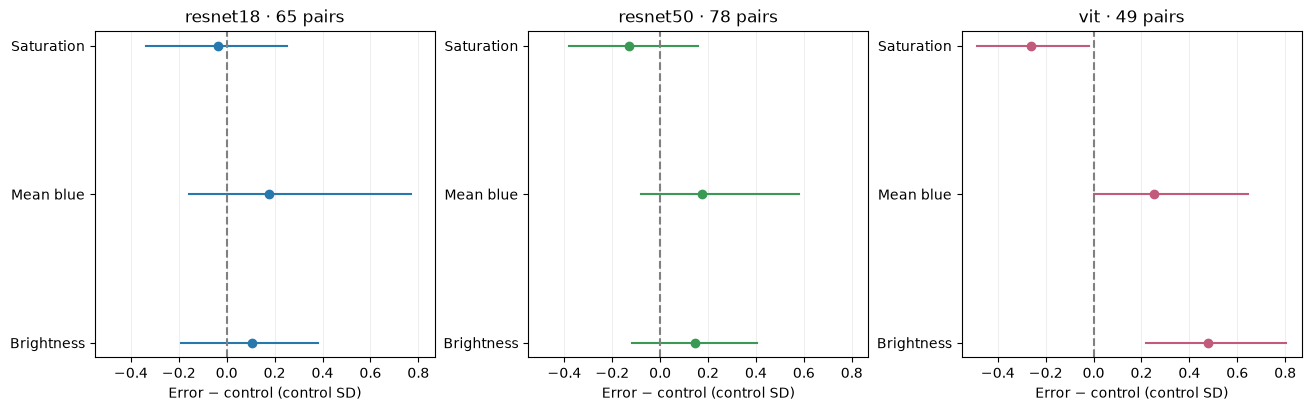

In [14]:
fig,axes=plt.subplots(1,3,figsize=(13,4),sharex=True,layout='constrained')
for m,(ax,name) in enumerate(zip(axes,model_names)):
    means=targeted[f'matching_{name}_feature_effect'];ci=targeted[f'matching_{name}_feature_ci']
    for j in range(3):
        ax.plot(ci[:,j],[j,j],color=model_colors[m]);ax.plot(means[j],j,'o',color=model_colors[m])
    ax.axvline(0,color='gray',ls='--');ax.set(title=f'{name} · {len(matched_pairs[m])} pairs',yticks=range(3),yticklabels=targeted['matching_feature_names'],xlabel='Error − control (control SD)');ax.grid(axis='x',alpha=.2)
plt.show()

Compare error-minus-control effects with zero and their paired-image 95% intervals under the tighter same-class, similar-confidence match. ViT errors are brighter by 0.48 control SD and less saturated by 0.26 SD, whereas both CNNs’ intervals include zero for all three features. These associations prioritize hypotheses but are sensitive to the retained cohort, correlated measurements and exploratory selection, rather than demonstrating a causal color mechanism.

## Saturation intervention — original-decision support and the destination class

The same HC errors and nearest same-class HC-correct controls receive saturation factors from 0.5 to 1.5. The left panels retain every tested factor, while the right panels isolate the destination-class distribution at ×0.5 to make class collapse visible. Controls can be reused, so these paired cohorts are descriptive rather than independent replicated samples.

**Cohort distinction:** These existing saturation curves use the original same-class HC-correct controls (threshold ≥90%, controls may be reused), not the tighter one-to-one confidence-caliper match above; no new saturation inference is implied.

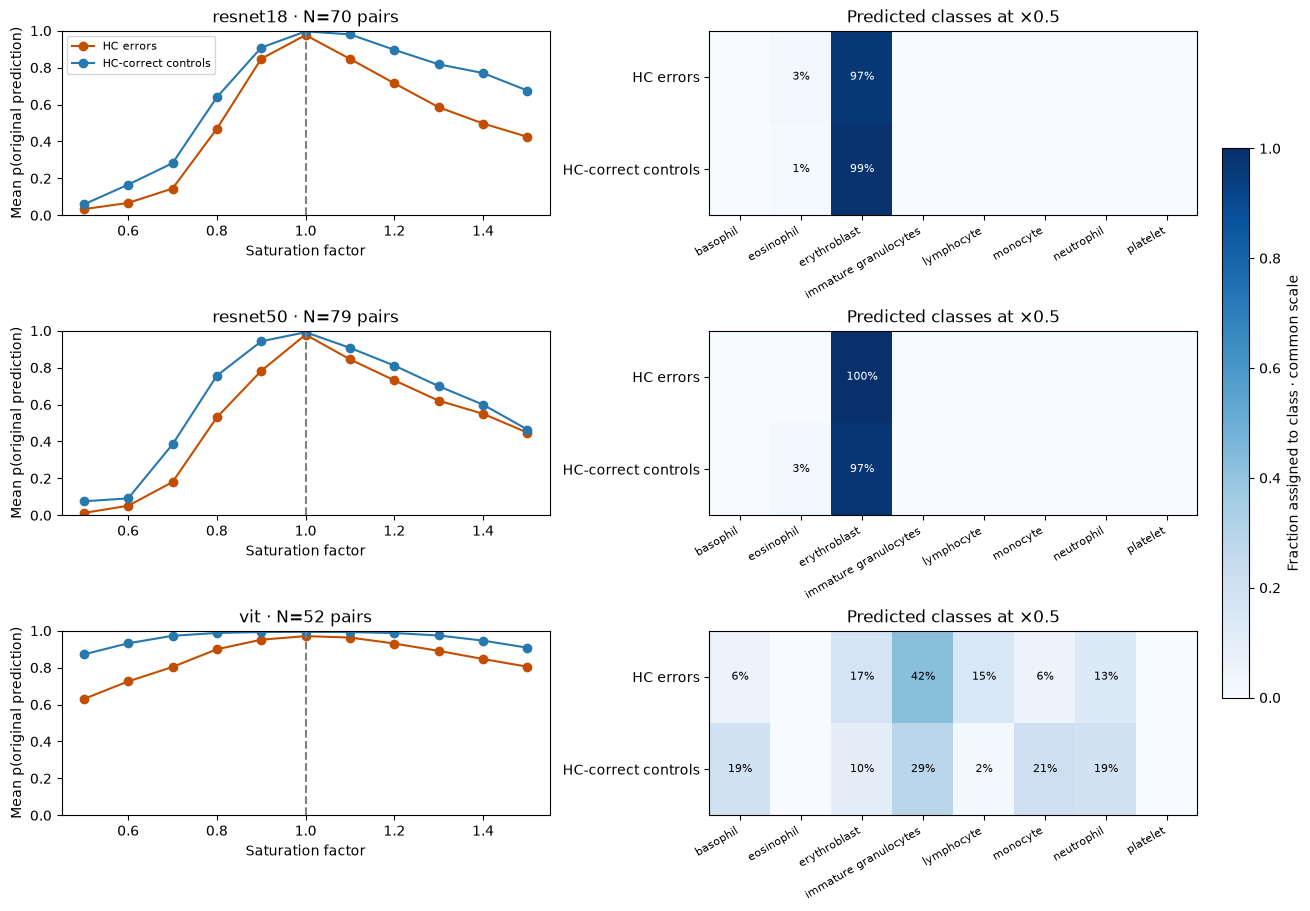

In [15]:
saturation_levels = analysis['saturation_levels']
saturation_index = int(np.argmin(np.abs(saturation_levels-.5)))
fig, axes = plt.subplots(3, 2, figsize=(13, 9), layout='constrained')
for m, name in enumerate(model_names):
    selected = analysis[f'{name}_saturation_ids']
    p = analysis[f'{name}_saturation_probabilities']
    np.testing.assert_allclose(p[:,5], probabilities[m,selected], atol=1e-5, rtol=1e-4)
    original = predicted[m,selected]
    retained = np.take_along_axis(p,original[:,None,:,None],axis=-1)[...,0]
    for role, title in enumerate(['HC errors','HC-correct controls']):
        axes[m,0].plot(saturation_levels,retained[role].mean(-1),'o-',label=title,
                       color=['#c44e00','#2678ad'][role])
    axes[m,0].axvline(1,color='gray',ls='--')
    axes[m,0].set(title=f'{name} · N={len(error_ids[m])} pairs',xlabel='Saturation factor',
                   ylabel='Mean p(original prediction)',ylim=(0,1))
    assigned = p[:,saturation_index].argmax(-1)
    distribution = np.stack([(assigned==c).mean(-1) for c in range(8)],axis=1)
    im = axes[m,1].imshow(distribution,vmin=0,vmax=1,cmap='Blues',aspect='auto')
    axes[m,1].set(title=f'Predicted classes at ×{saturation_levels[saturation_index]:g}',
                   xticks=range(8),xticklabels=class_names,yticks=[0,1],yticklabels=['HC errors','HC-correct controls'])
    plt.setp(axes[m,1].get_xticklabels(),rotation=30,ha='right',fontsize=8)
    for role,c in zip(*np.nonzero(distribution)):
        axes[m,1].text(c,role,f'{distribution[role,c]:.0%}',ha='center',va='center',fontsize=8,
                        color='white' if distribution[role,c]>.6 else 'black')
axes[0,0].legend(fontsize=8)
fig.colorbar(im,ax=axes[:,1],shrink=.7,label='Fraction assigned to class · common scale')
plt.show()

Follow original-decision support on the left and compare error/control destination classes at saturation ×0.5 on the right. ResNet18 assigns erythroblast to 68/70 errors and 69/70 controls, and ResNet50 to 79/79 errors and 77/79 controls, while ViT does not show that near-complete collapse. The shared CNN destination across different starting states supports color-dependent class assignment rather than a selective repair of initially wrong predictions.

### Occlusion: population versus tightly matched errors

Same 49 gray 4×4 patches and original-decision support; the bottom row now uses the confidence-caliper pairs, not the older RGB-near matches. The central contrast averages the nine fixed center patches per image before the paired, class-stratified bootstrap; patch locations are not independent samples or annotated cell structures.

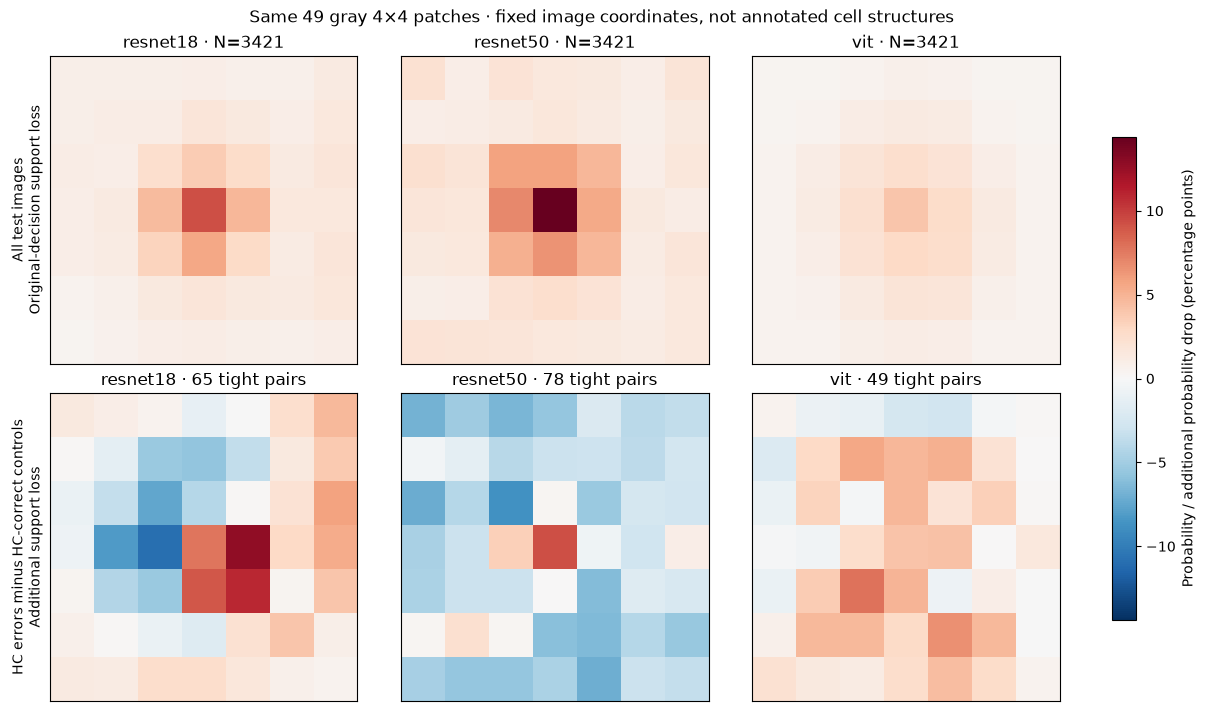

resnet18: original accuracy 96.61%; mean occluded accuracy 95.61%
resnet50: original accuracy 95.73%; mean occluded accuracy 94.23%
vit: original accuracy 96.99%; mean occluded accuracy 96.40%
resnet18: extra central loss +1.41 pp; paired-image 95% interval [-3.68, +6.52]
resnet50: extra central loss -1.22 pp; paired-image 95% interval [-5.73, +3.30]
vit: extra central loss +3.26 pp; paired-image 95% interval [-3.32, +10.58]


In [16]:
with np.load('predictions/occlusion_test.npz',allow_pickle=False) as saved:
    np.testing.assert_array_equal(saved['sample_index'],np.arange(len(labels)))
    np.testing.assert_array_equal(saved['baseline_probabilities'],probabilities)
    occluded = saved['probabilities']
original_support = np.take_along_axis(occluded,predicted[:,None,:,None],axis=-1)[...,0]
population_drop = (confidence[:,None]-original_support).transpose(0,2,1).reshape(3,len(labels),7,7)
paired_drop = []
for m,name in enumerate(model_names):
    selected = matched_pairs[m].T
    paired_drop.append((population_drop[m,selected[0]]-population_drop[m,selected[1]]).mean(0))
occlusion_maps = 100*np.stack([population_drop.mean(1),np.array(paired_drop)])
limit = max(np.abs(occlusion_maps).max(),1)
fig,axes = plt.subplots(2,3,figsize=(12,7),layout='constrained')
for row in range(2):
    for m,ax in enumerate(axes[row]):
        im=ax.imshow(occlusion_maps[row,m],cmap='RdBu_r',vmin=-limit,vmax=limit)
        ax.set(title=f'{model_names[m]} · '+(f'N={len(labels)}' if row==0 else f'{len(matched_pairs[m])} tight pairs'),xticks=[],yticks=[])
axes[0,0].set_ylabel('All test images\nOriginal-decision support loss')
axes[1,0].set_ylabel('HC errors minus HC-correct controls\nAdditional support loss')
fig.colorbar(im,ax=axes,shrink=.75,label='Probability / additional probability drop (percentage points)')
fig.suptitle('Same 49 gray 4×4 patches · fixed image coordinates, not annotated cell structures')
plt.show()
for m,name in enumerate(model_names):
    accuracy=(occluded[m].argmax(-1)==labels).mean()
    print(f'{name}: original accuracy {correct[m].mean():.2%}; mean occluded accuracy {accuracy:.2%}')
for m,name in enumerate(model_names):
    mean=targeted[f'matching_{name}_central_difference'].mean();ci=targeted[f'matching_{name}_central_ci']
    print(f'{name}: extra central loss {mean:+.2f} pp; paired-image 95% interval [{ci[0]:+.2f}, {ci[1]:+.2f}]')


Compare population sensitivity with the tightly matched error-minus-control maps and the central nine-patch intervals printed below. Additional central losses are +1.4, −1.2 and +3.3 percentage points for ResNet18, ResNet50 and ViT, with every 95% interval crossing zero, unlike the roughly 10-point contrasts under the older broader matching. The earlier error-specific spatial story is therefore not supported under tighter confidence control, and neither map identifies an anatomical causal feature.

### Approximate foreground/background color probes — inspect the masks first

Balanced 24 TEST images (three/class), originally correct and ≥90% confident in every model; these are **not** the error/control cohorts. Border-color distance defines a central stained-object core, then a two-pixel expansion tests sensitivity, with soft feathered boundaries; one visibly spilling mask (#769) was rejected before inference and replaced by #663.

**Important:** This is agent-reviewed gross overlap, **not expert cell segmentation**: pale cytoplasm can be assigned to the background complement, and expansion can include background or neighbor material. Foreground/background therefore mean approximate ROI/complement, not verified biological compartments; perturbation area and RMS dose are unequal, and three images per class can yield narrow or degenerate conditional bootstrap intervals. Full 24-image review and methods are preserved in the archive/source and cache.

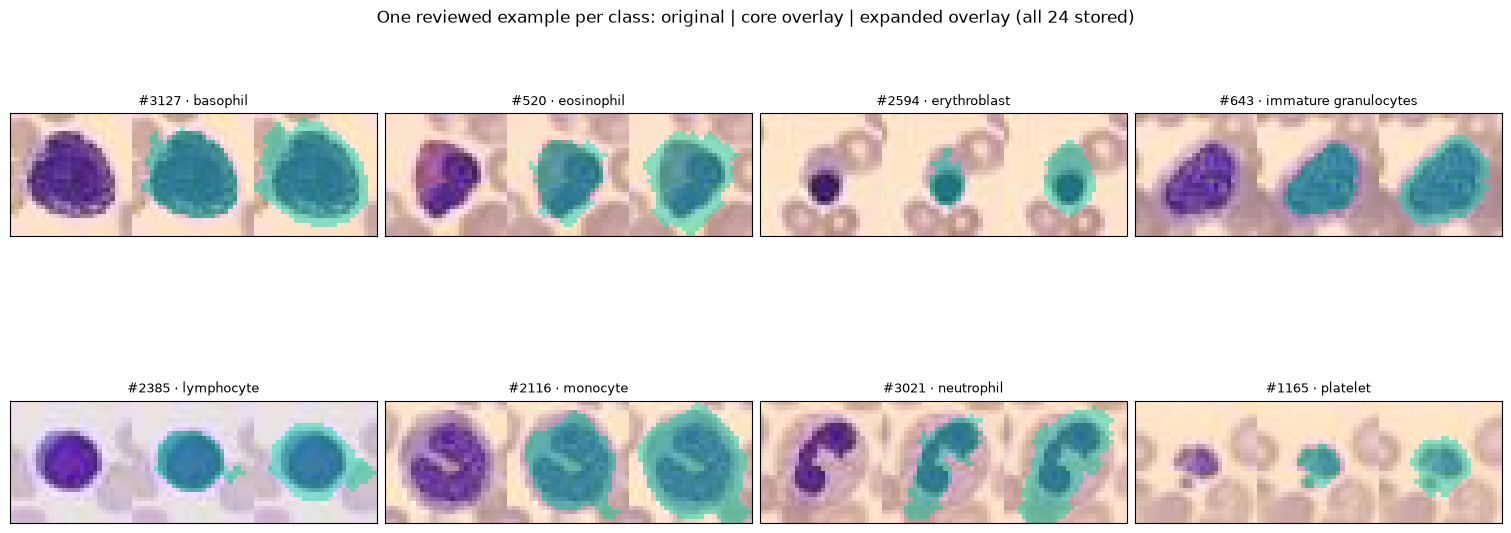

In [17]:
ids=targeted['roi_ids'];masks=targeted['roi_masks']
fig,axes=plt.subplots(2,4,figsize=(15,6),layout='constrained')
for cls,ax in enumerate(axes.flat):
    j=int(np.flatnonzero(labels[ids]==cls)[0]);i=ids[j];views=[images[i]]
    for mask in masks[:,j]:
        overlay=images[i].astype(float).copy();overlay[mask]=.55*overlay[mask]+.45*np.array([0,220,160]);views.append(overlay.astype(np.uint8))
    ax.imshow(np.concatenate(views,axis=1));ax.set(xticks=[],yticks=[],title=f'#{i} · {class_names[cls]}');ax.title.set_fontsize(9)
fig.suptitle('One reviewed example per class: original | core overlay | expanded overlay (all 24 stored)')
plt.show()

Compare the unmodified image with both overlays before interpreting any foreground/background intervention. The core generally tracks stained material and the expansion changes its spatial coverage, but pale cytoplasm and neighboring material remain visibly ambiguous. These approximate masks support a sensitivity probe only, not a definitive separation of cell and background evidence.

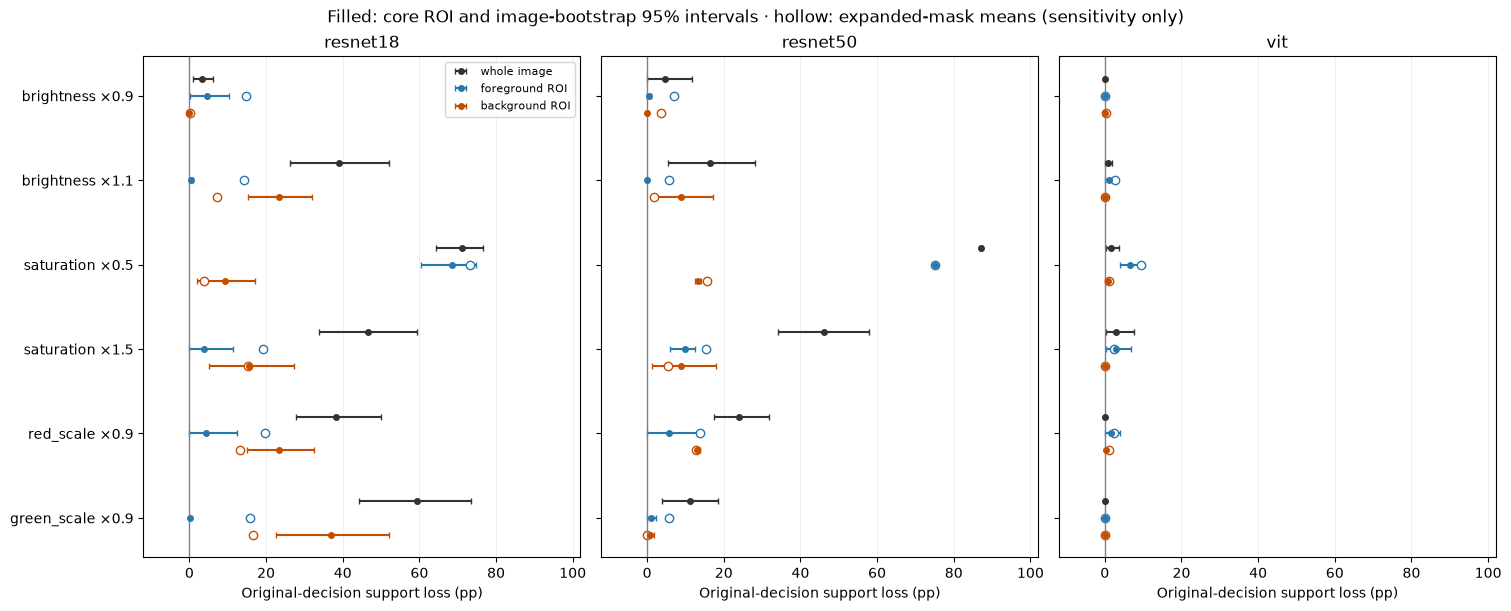

Core/expanded mean hard-mask area: 28.1%, 42.0%
Mean perturbation RMS on [0,1] intensity; whole / foreground / background, core mask:
brightness ×0.9: 0.0761 / 0.0244 / 0.0690
brightness ×1.1: 0.0644 / 0.0224 / 0.0575
saturation ×0.5: 0.0478 / 0.0324 / 0.0317
saturation ×1.5: 0.0458 / 0.0319 / 0.0294
red_scale ×0.9: 0.0470 / 0.0141 / 0.0430
green_scale ×0.9: 0.0405 / 0.0100 / 0.0379


In [18]:
q=targeted['roi_probabilities'];ids=targeted['roi_ids'];base=targeted['roi_baseline']
support=np.take_along_axis(q,base.argmax(-1)[:,None,None,None,:,None],axis=-1)[...,0]
drops=100*(base.max(-1)[:,None,None,None,:]-support)
rng=np.random.default_rng(43)
draws=np.column_stack([rng.choice(np.flatnonzero(labels[ids]==c),size=(2000,3)) for c in range(8)])
fig,axes=plt.subplots(1,3,figsize=(15,6),sharex=True,sharey=True,layout='constrained')
scopes=targeted['roi_scopes'];scope_colors=['#333333','#2678ad','#c44e00']
for m,ax in enumerate(axes):
    for scope in range(3):
        core=drops[m,0,:,scope];means=core.mean(-1);ci=np.quantile(core[:,draws].mean(-1),[.025,.975],axis=1)
        yy=np.arange(6)+(scope-1)*.2
        ax.errorbar(means,yy,xerr=[means-ci[0],ci[1]-means],fmt='o',color=scope_colors[scope],ms=4,capsize=2,label=str(scopes[scope]))
        if scope:
            ax.plot(drops[m,1,:,scope].mean(-1),yy,'o',mfc='white',mec=scope_colors[scope],ms=6)
    ax.axvline(0,color='gray',lw=1);ax.set(title=model_names[m],xlabel='Original-decision support loss (pp)',xlim=(-12,102),yticks=range(6),yticklabels=[f'{k} ×{v:g}' for k,v in zip(targeted['roi_kinds'],targeted['roi_levels'])]);ax.grid(axis='x',alpha=.2)
axes[0].invert_yaxis();axes[0].legend(fontsize=8)
fig.suptitle('Filled: core ROI and image-bootstrap 95% intervals · hollow: expanded-mask means (sensitivity only)')
plt.show()
print('Core/expanded mean hard-mask area:',', '.join(f'{mask.mean():.1%}' for mask in targeted['roi_masks']))
print('Mean perturbation RMS on [0,1] intensity; whole / foreground / background, core mask:')
for j,(kind,level) in enumerate(zip(targeted['roi_kinds'],targeted['roi_levels'])):
    print(f'{kind} ×{level:g}: '+ ' / '.join(f'{v:.4f}' for v in targeted['roi_rms'][0,j].mean(-1)))

**Interpretation:** Compare each scope within an intervention, treating hollow expanded-mask points as a mask-sensitivity check and the printed RMS values as unequal-dose warnings. At saturation ×0.5, core-ROI losses average 68/75/7 points versus background-complement losses 9/13/1 points for ResNet18/ResNet50/ViT, while some brightness/channel effects are more background- and mask-sensitive. The result supports saturation sensitivity in the approximate stained-object ROI but cannot establish anatomical localization or background reliance independently of mask error, unequal dose and nonlinear interactions.

## What survives the controls?

- **Disagreement and confidence:** Compare shared/exclusive images and class substitutions with reliability. The checkpoints share 18 HC errors despite different class-specific risks, and confidence exceeds observed accuracy. High confidence is therefore not a correctness guarantee, especially around the IG/neutrophil competition.
- **Stability and preprocessing:** Compare population robustness, selected flips and the paired interpolation control. Tiny edits can flip HC-correct predictions, while common bilinear resizing greatly narrows the selected noise-loss gap but worsens clean ResNet18 accuracy. Robustness here belongs to the checkpoint-plus-preprocessing pipeline, not architecture alone.
- **Appearance:** Compare the matched feature intervals, saturation destinations and approximate ROI probes. ViT brightness/saturation associations remain under tight matching, both CNNs show the broad saturation-to-erythroblast attractor, and desaturating stained-object ROIs strongly affects CNN support. This prioritizes color-related hypotheses without proving a biological cause or clean foreground/background separation.
- **A weakened explanation:** Compare the old archived occlusion contrast with the new tightly matched intervals. The old roughly 10-point extra central losses shrink to +1.4/−1.2/+3.3 points and all intervals cross zero. Stronger central dependence of HC errors is not supported after this tighter confidence control.

**Limits:** Exploratory TEST-only analysis, correlated features and no multiple-comparison correction; unmatched errors are excluded from tight-pair results. Small balanced ROI/interpolation cohorts are not full-population prevalence estimates, bootstrap intervals condition on the selected cohort/matching and do not incorporate model-training or segmentation uncertainty, and image edits may invalidate labels. [archive.ipynb](archive.ipynb) retains every original/intermediate plot, output and interpretation, including all entropy/PCA work and the source for reproducing the targeted controls.